In [1]:
import pandas as pd
import numpy as np
import sys
import xarray as xr
import seaborn as sns
from scipy import stats
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import glob
# set warning to ignore
import warnings
warnings.filterwarnings("ignore", category=UserWarning, append=True)
sns.set_context("talk", font_scale=0.7)

In [266]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import ecplot as ecplt

stratus_regions = {
    'SEA': {'lat': (-22.5, -2.5), 'lon': (-5, 15)}, # 'lat': (-20, -10), 'lon': (0, 10) original SEA from Klein and Hartmann
    'NEA': {'lat': (10, 30), 'lon': (-40, -20)},
    'SEP': {'lat': (-22.5, -2.5), 'lon': (-95, -75)},
    'NEP': {'lat': (15, 35), 'lon': (-135, -115)},
}
stratus_region_names = {
    0: 'SEA',
    1: 'NEA',
    2: 'SEP',
    3: 'NEP',
}

# Combine judge results with ACMCAP and XMET

In [300]:
region = 'SEA'

## Load the judge dataset

In [301]:
judge_results = f'/home/jmayer/ACI_research/Code/resources_mesoscale_structure/judge_msi_results_{region}.csv'
df_judge = pd.read_csv(judge_results)
df_judge['time_mid'] = pd.to_datetime(df_judge['time_mid'])

In [302]:
df_judge

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,ocean_flag,cats,cert,orbit
0,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.000000,0.397090,0.177294,0.048523,1.0,5.0,0.987178,01005E
1,256.5,2024-08-01 13:33:57.907422976,6.850008,-3.579188,-4.053551,-3.010381,0.000000,0.125214,0.194699,0.027893,1.0,5.0,0.996087,01005E
2,384.5,2024-08-01 13:34:05.971490944,6.752782,-4.100778,-4.575092,-3.531977,0.000000,1.163266,0.292969,0.089417,1.0,5.0,0.997600,01005E
3,512.5,2024-08-01 13:34:14.035559040,6.655464,-4.622335,-5.096593,-4.053551,0.000000,4.196482,0.607740,0.202087,1.0,5.0,0.979517,01005E
4,640.5,2024-08-01 13:34:22.099622976,6.557949,-5.143854,-5.618070,-4.575092,0.000000,3.167468,0.615831,0.170166,1.0,5.0,0.862957,01005E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13145,4224.5,2025-11-17 14:02:17.423578112,-3.875664,-19.752005,-20.224516,-19.183390,0.045349,3.322360,0.822761,0.788696,1.0,0.0,0.626594,08365E
13146,4352.5,2025-11-17 14:02:25.487642048,-3.980972,-20.272604,-20.744983,-19.703984,0.101868,5.752044,0.851977,0.717163,1.0,0.0,0.517516,08365E
13147,4480.5,2025-11-17 14:02:33.551705984,-4.086639,-20.793140,-21.265368,-20.224516,0.170410,5.781100,0.927715,0.641541,1.0,3.0,0.393571,08365E
13148,4608.5,2025-11-17 14:02:41.615771008,-4.192802,-21.313596,-21.785653,-20.744983,0.284119,3.856775,0.827008,0.715149,1.0,3.0,0.785090,08365E


In [303]:
df_judge.time_mid.min(), df_judge.time_mid.max()

(Timestamp('2024-08-01 13:33:49.843358976'),
 Timestamp('2025-11-17 14:02:49.679835008'))

<Axes: >

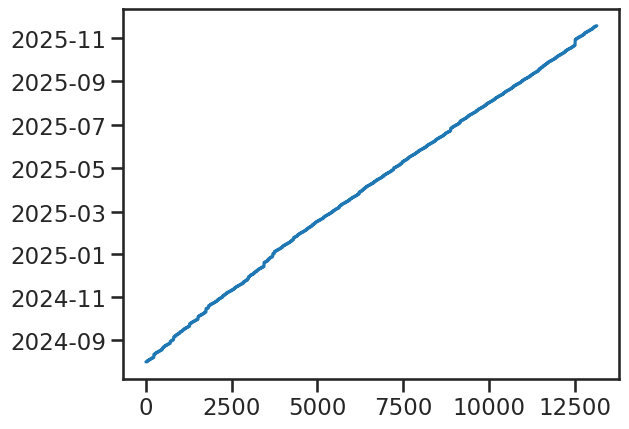

In [304]:
pd.to_datetime(df_judge.time_mid).plot()

## Load the dataset for vertical structure

In [305]:
dataset_filename = f'/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_StCu_{region}.h5'
df_acmcap = pd.read_hdf(dataset_filename, key='StCu')

In [306]:
df_acmcap['acmcap_cloud_flag'] = np.where(df_acmcap.lwp > 0, 1, 0)

acmcap_variables_of_interest = ['daytime', 'acmcap_cloud_flag', 'lwp', 'ER', 'ER_passive_perspective', 'Nd', 'lwp_error',
       'Nd_error', 'liquid_classification_mean', 'liquid_optical_depth', 'cth',
       'cbh', 'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer',
       'N_cloudy_pixels', 'rain_rate_mean', 'rain_rate_surface',
       'rain_rate_cbh', 'rain_rate_max', 'rain_rate_subcloud', 'rwc_cbh',
       'rwp', 'rwp_subcloud', 'rain_median_volume_diameter',
       'rain_normalized_number_concentration', 'doppler_velocity_mean']

# make sure to set variables to NaN where there are no clouds
for var in acmcap_variables_of_interest:
    if var != 'acmcap_cloud_flag':
       df_acmcap[var] = df_acmcap[var].where(df_acmcap['acmcap_cloud_flag'] == 1, np.nan)

In [307]:
df_acmcap.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1532544 entries, 0 to 1532543
Data columns (total 37 columns):
 #   Column                                Non-Null Count    Dtype         
---  ------                                --------------    -----         
 0   along_track                           1532544 non-null  int64         
 1   time                                  1532544 non-null  datetime64[ns]
 2   latitude                              1532544 non-null  float64       
 3   longitude                             1532544 non-null  float64       
 4   stratus_region_index                  1532544 non-null  int64         
 5   daytime                               969181 non-null   object        
 6   lwp                                   969181 non-null   float32       
 7   ER                                    969181 non-null   float32       
 8   ER_passive_perspective                969181 non-null   float32       
 9   Nd                                    969181 non-nu

## Combine the information of both datasets

In [308]:
orbits = df_judge.orbit.unique()

In [309]:
print('missing orbits in judge results:')
for orb in df_acmcap.orbit.unique():
    if orb not in orbits and orb[-1] in ['D','E']:
        print(orb, '; at ', df_acmcap[df_acmcap.orbit == orb].time.iloc[0])

missing orbits in judge results:
03914E ; at  2025-02-04 12:47:12.741172992
04692E ; at  2025-03-26 12:46:20.483162112
06637E ; at  2025-07-29 12:45:10.650576512
07026E ; at  2025-08-23 12:45:11.290966528


In [310]:
df = pd.DataFrame(columns=['scene_id', 'stratus_region_index'] 
                  + list(df_judge.columns) 
                  + acmcap_variables_of_interest 
                  + ['cbh_m_max', 'cth_m_max', 'cbh_m_min', 'cth_m_min', 'N_cloudy_pixels_std', 'N_cloudy_pixels_max', 'rwp_std', 'rwp_max', 'lwp_std', 'lwp_max'])
i = 0
j = 0
unique_orbits = df_judge.orbit.unique()
print(f'Number of unique orbits in judge results: {len(unique_orbits)}')
print('Adding ACMCAP data to judge results by taking the mean for each scene...')
for orbit in unique_orbits:
    j += 1
    print(j, '/',len(unique_orbits), '; ', orbit)
    df_judge_orbit = df_judge[df_judge['orbit']==orbit]
    df_acmcap_orbit = df_acmcap[df_acmcap['orbit']==orbit]

    if df_acmcap_orbit.empty:
        print(f'No matching orbit {orbit} in dataset')
    else:
        for idx, row in df_judge_orbit.iterrows():
            lat_min = row['lat_min']
            lat_max = row['lat_max']
            df_acmcap_scene = df_acmcap_orbit[(df_acmcap_orbit.latitude >= lat_min) & (df_acmcap_orbit.latitude <= lat_max)]

            if len(df_acmcap_scene) > 0:
                df_acmcap_scene_mean = df_acmcap_scene[acmcap_variables_of_interest + ['time']].mean()
                # add std, max, min for selected variables
                df_acmcap_scene_mean['cbh_m_max'] = df_acmcap_scene['cbh_m'].max()
                df_acmcap_scene_mean['cth_m_max'] = df_acmcap_scene['cth_m'].max()
                df_acmcap_scene_mean['cbh_m_min'] = df_acmcap_scene['cbh_m'].min()
                df_acmcap_scene_mean['cth_m_min'] = df_acmcap_scene['cth_m'].min()
                df_acmcap_scene_mean['N_cloudy_pixels_std'] = df_acmcap_scene['N_cloudy_pixels'].std()
                df_acmcap_scene_mean['N_cloudy_pixels_max'] = df_acmcap_scene['N_cloudy_pixels'].max()
                df_acmcap_scene_mean['rwp_std'] = df_acmcap_scene['rwp'].std()
                df_acmcap_scene_mean['rwp_max'] = df_acmcap_scene['rwp'].max()
                df_acmcap_scene_mean['lwp_std'] = df_acmcap_scene['lwp'].std()
                df_acmcap_scene_mean['lwp_max'] = df_acmcap_scene['lwp'].max()
                df_acmcap_scene_mean['ER_max'] = df_acmcap_scene['ER'].max()
                
                # sanity check
                time_diff = abs((df_acmcap_scene_mean.time - row['time_mid']).total_seconds())
                if time_diff > 1:
                    print(f'Warning: time difference between judge result and acmcap mean is {time_diff} seconds for orbit {orbit}')

                # combine row and df_acmcap_scene_mean and add to df_comb
                combined_dict = {**row.to_dict(), **df_acmcap_scene_mean.to_dict()}
                combined_dict['scene_id'] = i
                combined_dict['stratus_region_index'] = 2 if region == 'SEP' else 3 if region == 'NEP' else 0 if region == 'SEA' else 1 if region == 'NEA' else -1
                df.loc[i] = combined_dict
                i += 1
            else:
                print(f'No matching latitudes for orbit {orbit} between {lat_min} and {lat_max}')

Number of unique orbits in judge results: 424
Adding ACMCAP data to judge results by taking the mean for each scene...
1 / 424 ;  01005E
2 / 424 ;  01021E
3 / 424 ;  01036E
4 / 424 ;  01052E
5 / 424 ;  01067E
6 / 424 ;  01083E
7 / 424 ;  01098E
8 / 424 ;  01160E
9 / 424 ;  01176E
10 / 424 ;  01192E
11 / 424 ;  01207E
12 / 424 ;  01223E
13 / 424 ;  01238E
14 / 424 ;  01254E
15 / 424 ;  01269E
16 / 424 ;  01300E
17 / 424 ;  01316E
18 / 424 ;  01347E
19 / 424 ;  01363E
20 / 424 ;  01378E
21 / 424 ;  01394E
22 / 424 ;  01409E
23 / 424 ;  01456E
24 / 424 ;  01472E
25 / 424 ;  01487E
26 / 424 ;  01549E
27 / 424 ;  01565E
28 / 424 ;  01581E
29 / 424 ;  01596E
30 / 424 ;  01612E
31 / 424 ;  01627E
32 / 424 ;  01658E
33 / 424 ;  01674E
34 / 424 ;  01689E
35 / 424 ;  01705E
36 / 424 ;  01721E
37 / 424 ;  01736E
38 / 424 ;  01752E
39 / 424 ;  01767E
40 / 424 ;  01783E
41 / 424 ;  01829E
42 / 424 ;  01845E
43 / 424 ;  01861E
44 / 424 ;  01876E
45 / 424 ;  01892E
46 / 424 ;  01907E
47 / 424 ;  0192

# Read in combined dataset

In [ ]:
#dataset_filename = '/home/jmayer/ACI_research/Code/resources/ACMCAP_XMET_judge_StCu_Jun-Aug.h5'
#df = pd.read_hdf(dataset_filename, key='StCu')

In [ ]:
df.time.min(), df.time.max()

(Timestamp('2025-06-01 13:26:02.599795968'),
 Timestamp('2025-08-31 22:38:59.645495808'))

## Sanity checks

In [ ]:
valid_rwp_and_rwp_subcloud = ~np.isnan(df.rwp) & ~np.isnan(df.rwp_subcloud)
(df[valid_rwp_and_rwp_subcloud].rwp >= df[valid_rwp_and_rwp_subcloud].rwp_subcloud).dropna().all()

np.True_

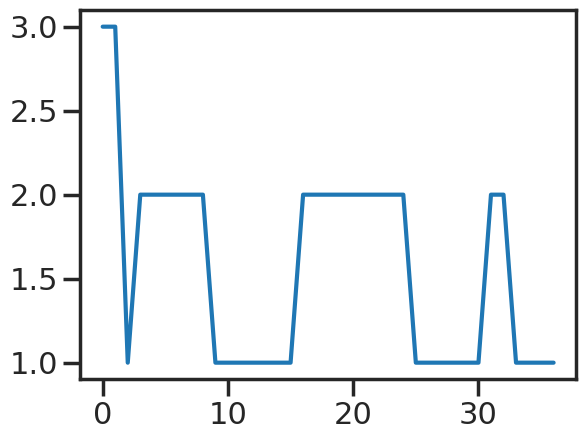

In [17]:
dfex = df[df.orbit == '06486E']
dfex = dfex.reset_index()
dfex.cats.plot()
plt.show()

<Axes: ylabel='Frequency'>

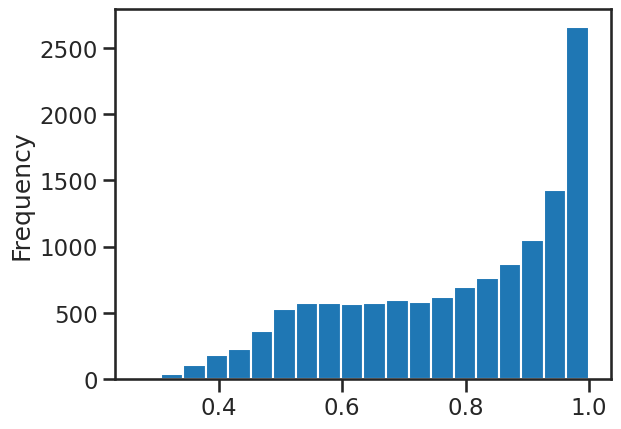

In [103]:
df.cert.plot.hist(bins=20)

<Axes: ylabel='Frequency'>

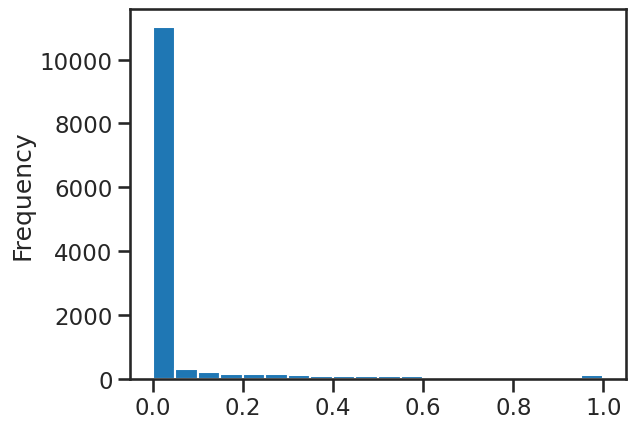

In [104]:
df['ice_flag'].astype(float).plot.hist(bins=20)

# Filters

## Filter dataset

In [311]:
# we only want scenes over ocean
df = df[(df.ocean_flag == 1)]

In [312]:
dffil = df.copy()

# filters:
# 1) ice-free; 
# 2) high confidence; 
# 3) at least 10% cloud cover in MCOP
dffil = dffil[
    (dffil.ice_flag == 0) &
    (dffil.cert > 0.75) & 
    (dffil.cloud_cover >= 0.1)
              ]

In [313]:
(((df.ice_flag == 0)).sum()/len(df), 
 ((df.cert > 0.75)).sum()/len(df), 
 ((df.cloud_cover >= 0.1)).sum()/len(df), 
 len(dffil)/len(df))

(np.float64(0.8115070460461359),
 np.float64(0.6051521407414057),
 np.float64(0.9312449510815906),
 0.4608203931424468)

In [314]:
df

,scene_id,stratus_region_index,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,...,cbh_m_max,cth_m_max,cbh_m_min,cth_m_min,N_cloudy_pixels_std,N_cloudy_pixels_max,rwp_std,rwp_max,lwp_std,lwp_max
0,0,0,128.5,2024-08-01 13:33:49.843358976,6.947272,-3.057578,-3.531977,-2.492825,0.000000,0.397090,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0,256.5,2024-08-01 13:33:57.907422976,6.850008,-3.579188,-4.053551,-3.010381,0.000000,0.125214,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0,384.5,2024-08-01 13:34:05.971490944,6.752782,-4.100778,-4.575092,-3.531977,0.000000,1.163266,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,0,512.5,2024-08-01 13:34:14.035559040,6.655464,-4.622335,-5.096593,-4.053551,0.000000,4.196482,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0,640.5,2024-08-01 13:34:22.099622976,6.557949,-5.143854,-5.618070,-4.575092,0.000000,3.167468,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13145,13145,0,4224.5,2025-11-17 14:02:17.423578112,-3.875664,-19.752005,-20.224516,-19.183390,0.045349,3.322360,...,1557.575562,1762.690430,510.086884,1024.857056,1.605174,10.0,0.005113,0.027252,0.038650,0.242232
13146,13146,0,4352.5,2025-11-17 14:02:25.487642048,-3.980972,-20.272604,-20.744983,-19.703984,0.101868,5.752044,...,1339.245728,1659.633667,510.086884,1024.857056,1.594811,10.0,0.005753,0.026725,0.045848,0.419502
13147,13147,0,4480.5,2025-11-17 14:02:33.551705984,-4.086639,-20.793140,-21.265368,-20.224516,0.170410,5.781100,...,1247.400146,1650.869629,200.909164,1228.821167,1.701258,9.0,0.005329,0.026725,0.046284,0.419502
13148,13148,0,4608.5,2025-11-17 14:02:41.615771008,-4.192802,-21.313596,-21.785653,-20.744983,0.284119,3.856775,...,1335.144653,1455.382324,200.656281,1228.821167,1.532789,7.0,0.000710,0.004509,0.011325,0.045188


In [315]:
dffil

,scene_id,stratus_region_index,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,...,cbh_m_max,cth_m_max,cbh_m_min,cth_m_min,N_cloudy_pixels_std,N_cloudy_pixels_max,rwp_std,rwp_max,lwp_std,lwp_max
3,3,0,512.5,2024-08-01 13:34:14.035559040,6.655464,-4.622335,-5.096593,-4.053551,0.0,4.196482,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0,640.5,2024-08-01 13:34:22.099622976,6.557949,-5.143854,-5.618070,-4.575092,0.0,3.167468,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,20,0,2688.5,2024-08-01 13:36:31.124659520,4.978599,-13.484226,-13.957365,-12.915578,0.0,1.737344,...,1244.527954,1657.187988,832.925781,1027.205322,1.169515,8.0,0.001907,0.012917,0.038242,0.232832
21,21,0,2816.5,2024-08-01 13:36:39.188723904,4.878013,-14.005127,-14.478184,-13.436505,0.0,1.656852,...,1243.863525,1657.187988,720.588806,1027.205322,1.363814,9.0,0.001903,0.012917,0.055170,0.314089
25,25,0,3328.5,2024-08-01 13:37:11.444980992,4.473244,-16.088248,-16.560865,-15.519672,0.0,3.036209,...,1139.485474,1448.157593,622.990784,723.196472,1.789585,7.0,0.013649,0.038285,0.015093,0.068686
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13129,13129,0,2176.5,2025-11-17 14:00:08.398545920,-2.239807,-11.413020,-11.887378,-10.844164,0.0,2.383991,...,1036.684814,1252.785522,312.377594,522.705994,1.153856,7.0,0.000000,0.000000,0.013894,0.083540
13130,13130,0,2304.5,2025-11-17 14:00:16.462610048,-2.339890,-11.934625,-12.408905,-11.365809,0.0,1.839559,...,1043.881226,1252.557251,312.377594,522.705994,1.230858,7.0,0.000270,0.001422,0.019632,0.090640
13131,13131,0,2432.5,2025-11-17 14:00:24.526673984,-2.440239,-12.456190,-12.930373,-11.887378,0.0,2.264764,...,1043.881226,1253.391479,620.572998,1033.827393,1.262297,7.0,0.000317,0.001422,0.019304,0.090640
13133,13133,0,2688.5,2025-11-17 14:00:40.654802496,-2.641617,-13.499183,-13.973230,-12.930373,0.0,3.185146,...,1042.844604,1248.475952,526.909973,731.522034,1.237952,7.0,0.003434,0.029435,0.020269,0.096312


# Analysis

In [256]:
sns.set_context("talk", font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

In [257]:
# get 6 distinct colors from the viridis colormap
cmap = matplotlib.cm.get_cmap('viridis', 6)
catcolors = [cmap(i) for i in range(cmap.N)]

#colors = ['#1f77b4', '#2ca02c', '#ff7f0e',  '#d62728', '#e377c2', '#8c564b', 'black']

line_styles = [(0, (3, 1, 1, 1)), '-', '--', '-.', (0,(3,1,1,1,1,1)), ':']

In [258]:
cats_names = {
    0: 'Solid Stratus',
    1: 'Closed MCC',
    2: 'Open MCC',
    3: 'Disorg. MCC',
    4: 'Clustered Cu',
    5: 'Suppr. Cu'
    }

palette_catscolors = {i: catcolors[i] for i in range(6)}
palette_catscolors[6] = 'lightgray'  # for unclassified

In [259]:
from matplotlib.lines import Line2D

# Custom legend with line styles
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in range(6)
]

In [260]:
def histplot_with_style(cluster_id, ax, data, x, bins, **kwargs):
    sns.histplot(
        ax=ax, data=data[data['cats'] == cluster_id], x=x, bins=bins,
        element='step', stat='probability', fill=True, alpha=0.2, lw=0, kde=True,
        color=catcolors[cluster_id], line_kws={'ls':line_styles[cluster_id], 'lw':3},
        **kwargs
    )

## Number of samples

In [261]:
dffil.scene_id.unique()

array([    2,     3,     4, ..., 13008, 13012, 13013], shape=(4809,))

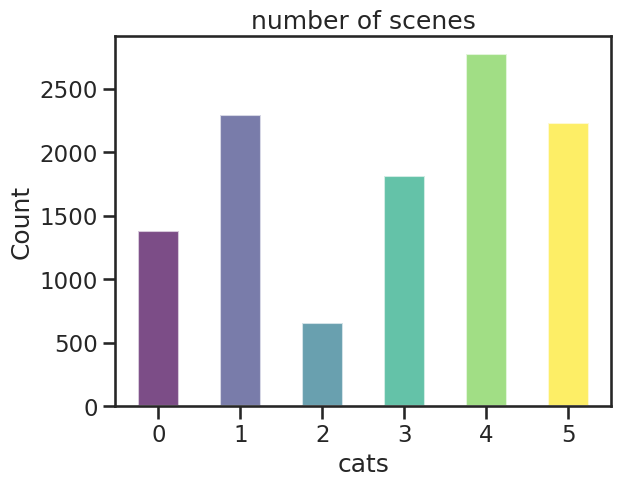

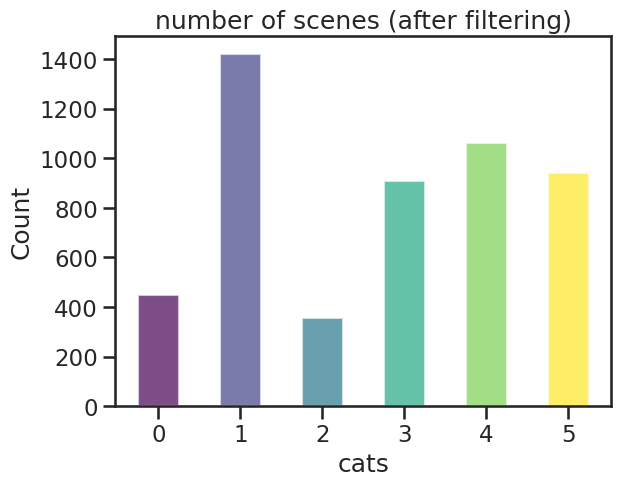

In [316]:
import matplotlib.pyplot as plt

cats = df.groupby('scene_id')['cats'].mean()
bins = np.arange(-0.25, 5.75, 0.5)
counts, edges = np.histogram(cats, bins=bins)
plt.figure()
for i in range(len(counts)):
    plt.bar(edges[i]+0.25, counts[i], width=0.5, color=catcolors[i//2], alpha=0.7)
plt.xlabel('cats')
plt.ylabel('Count')
plt.title('number of scenes')
plt.show()

cats = dffil.groupby('scene_id')['cats'].mean()
bins = np.arange(-0.25, 5.75, 0.5)
counts, edges = np.histogram(cats, bins=bins)
plt.figure()
for i in range(len(counts)):
    plt.bar(edges[i]+0.25, counts[i], width=0.5, color=catcolors[i//2], alpha=0.7)
plt.xlabel('cats')
plt.ylabel('Count')
plt.title('number of scenes (after filtering)')
plt.show()

## geographic distribution

In [112]:
from matplotlib import colors
from mpl_toolkits.basemap import Basemap

In [113]:
def bmap(ax=None, drawlines=True, llr=None, par_labs=[1, 0, 0, 0], mer_labs=[0, 0, 0, 1], 
         merspace=5, parspace=5, **kwargs):

    if ax is None:
        fig, ax = plt.subplots()

    lat_range = llr['lat']
    lon_range = llr['lon']
    
    if 'projection' not in kwargs.keys():
        kwargs['projection'] = 'cyl'
        kwargs['rsphere'] =(6378137.00, 6356752.3142)
    m = Basemap(llcrnrlon=lon_range[0], llcrnrlat=lat_range[0],
                urcrnrlon=lon_range[1],  urcrnrlat=lat_range[1],
                ax=ax, resolution='l', **kwargs)
    if drawlines:
        m.drawparallels(np.arange(-90., 90., parspace), labels=par_labs, fontsize=14)
        m.drawmeridians(np.arange(-180., 180., merspace), labels=mer_labs, fontsize=14)
    m.drawcoastlines()
    m.fillcontinents(color="white", lake_color="white")

    return m

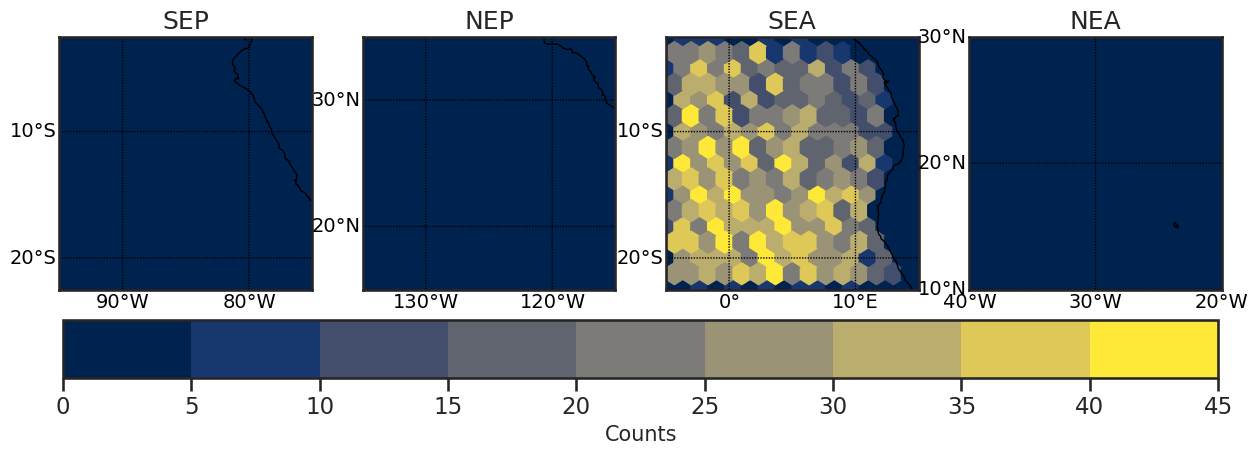

In [317]:
ticks = np.linspace(0, 50, 11)[:-1]
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)

fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(15, 5))
axn = axs.flatten()
for i, ax in enumerate(axn):
    stratus_region_order = [2, 3, 0, 1]
    sr = stratus_region_order[i]
    plot_df = dffil[(dffil.stratus_region_index == sr)]
    stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
    llr = stratus_regions[stratus_region_names[sr]]

    b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
    image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=15, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
    image.cmap.set_under('lightgrey')
    ax.set_title(stratus_region_names[sr])

plt.subplots_adjust(hspace=0.2, wspace=0.2)
cb = plt.colorbar(image, ax=axn, orientation='horizontal', pad=0.08)
cb.set_label("Counts", fontsize=15)

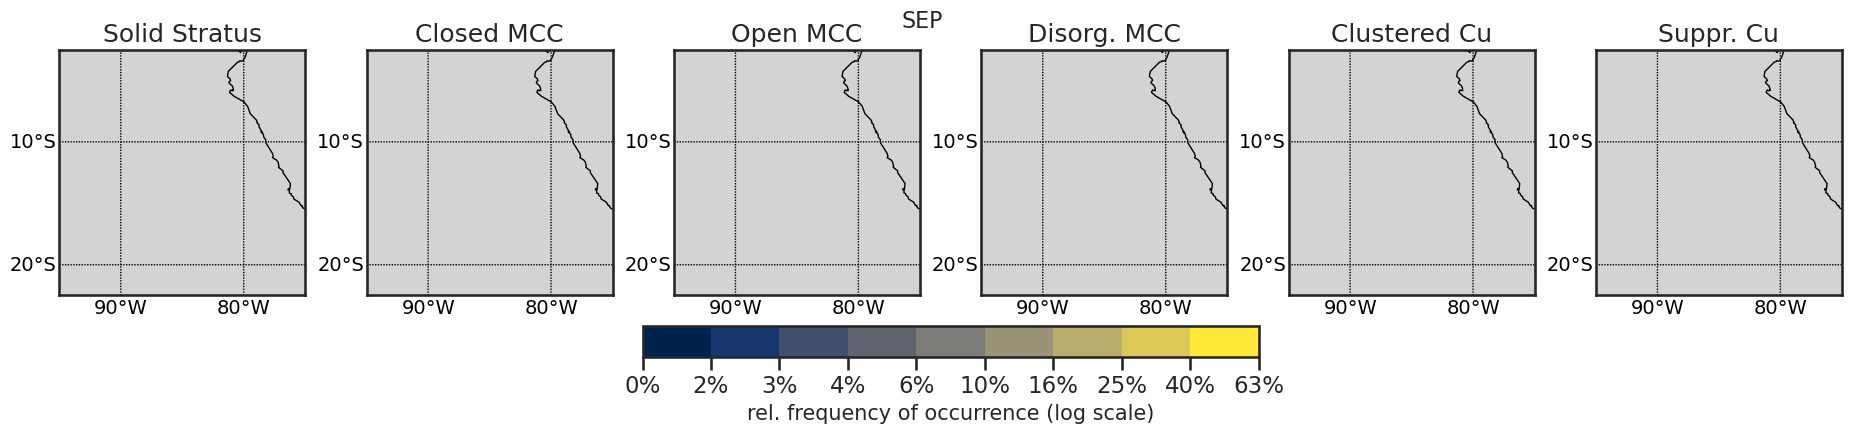

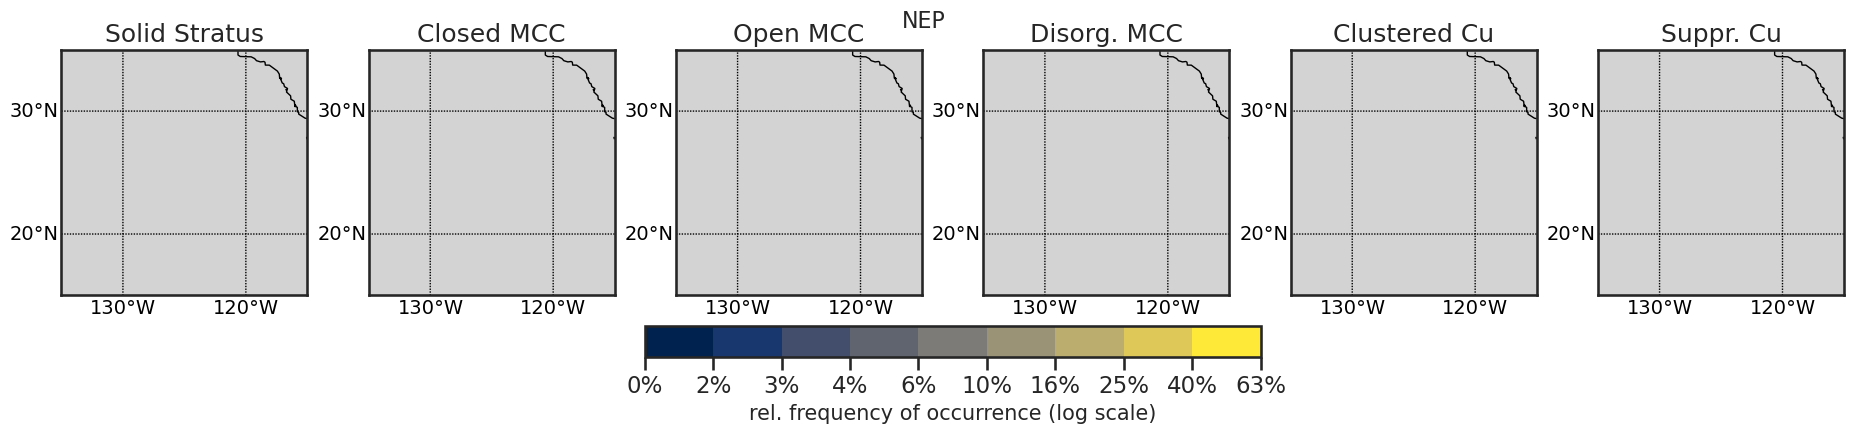

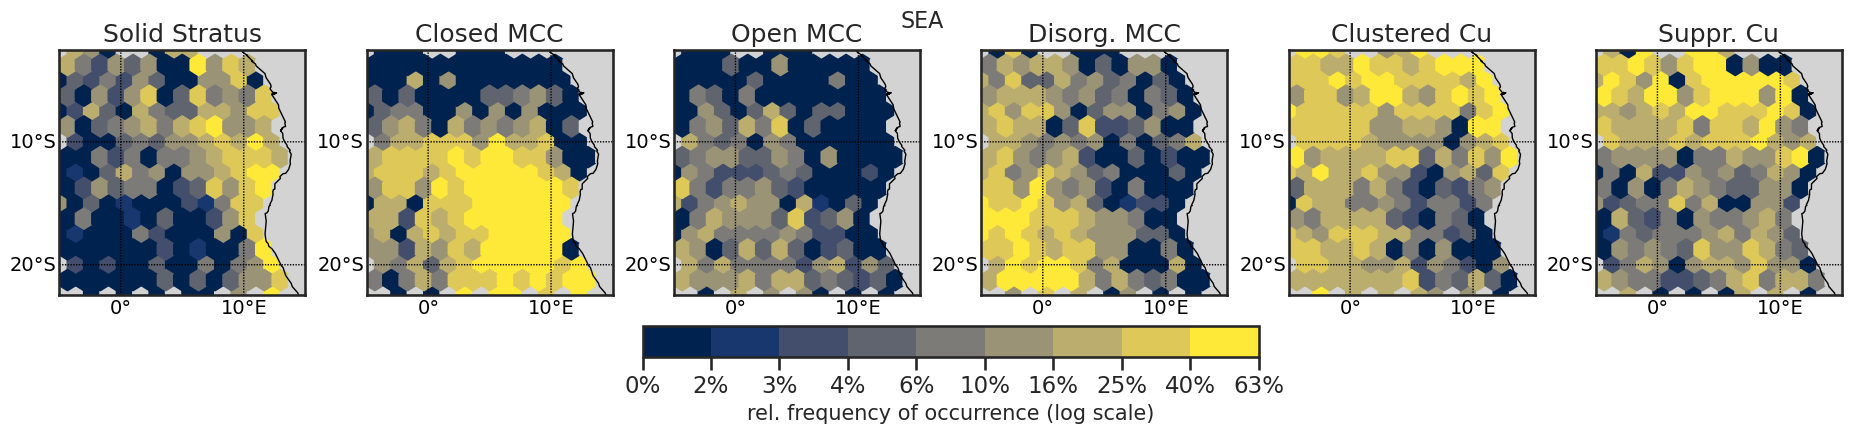

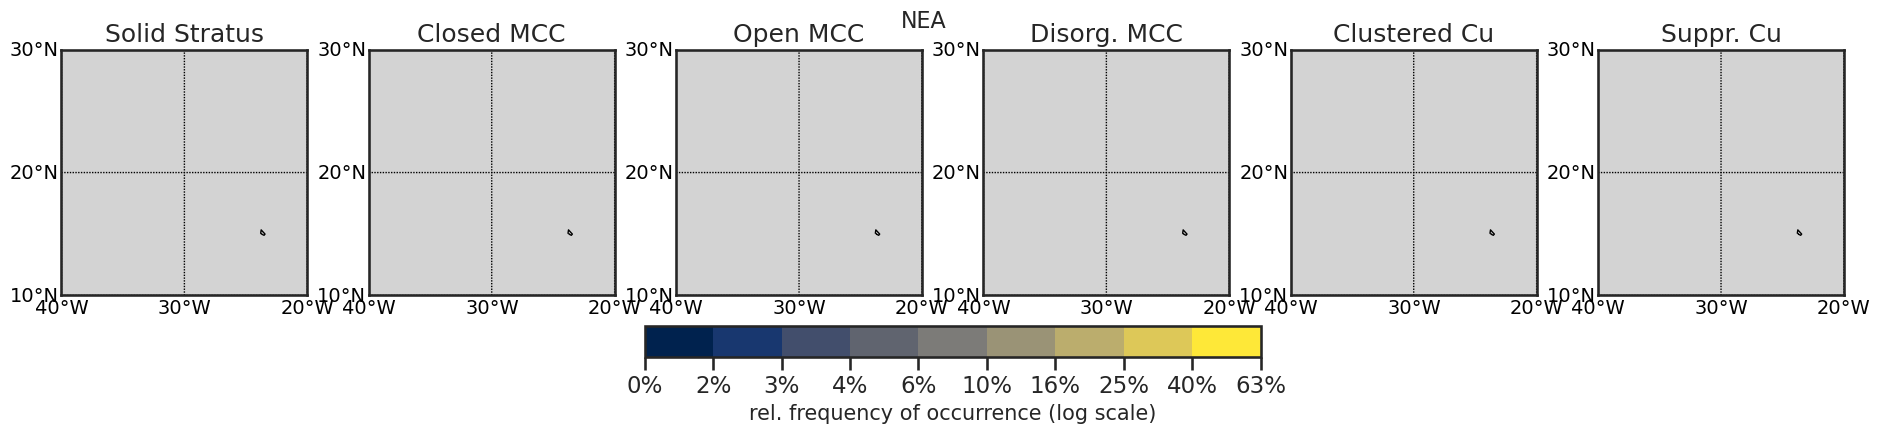

In [318]:
#ticks = np.linspace(0, 1, 11)[:-1]
#bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
#lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)
ticks = np.logspace(-2, 0, 11)[:-1]
ticks[0]=0
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

for j in range(4):
    stratus_region_order = [2, 3, 0, 1]
    sr = stratus_region_order[j]
    stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
    llr = stratus_regions[stratus_region_names[sr]]

    gridsize = 15
    fig, ax = plt.subplots()
    b = bmap(ax=ax, llr=llr)
    plot_df = dffil[(dffil.stratus_region_index == sr)]
    image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
    all_counts = image.get_array()+1
    plt.close()

    fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(23, 4), sharex=True, sharey=True)
    plt.suptitle(f'{stratus_region_names[sr]}', fontsize=16)
    axn = axs.flatten()
    for i, ax in enumerate(axn):
        plot_df = dffil[(dffil.stratus_region_index == sr) & (dffil['cats'] == i)]

        b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
        image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
        normed_counts = image.get_array()/all_counts
        normed_counts[all_counts<5] = -1
        
        image.set_array(normed_counts)
        image.cmap.set_under('lightgrey')
        ax.set_title(cats_names[i])

    plt.subplots_adjust(hspace=0.5, wspace=0.25)
    cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.1)
    cb.set_ticklabels([f"{i:0.0%}" for i in ticks])
    cb.set_label("rel. frequency of occurrence (log scale)", fontsize=15)
    plt.show()

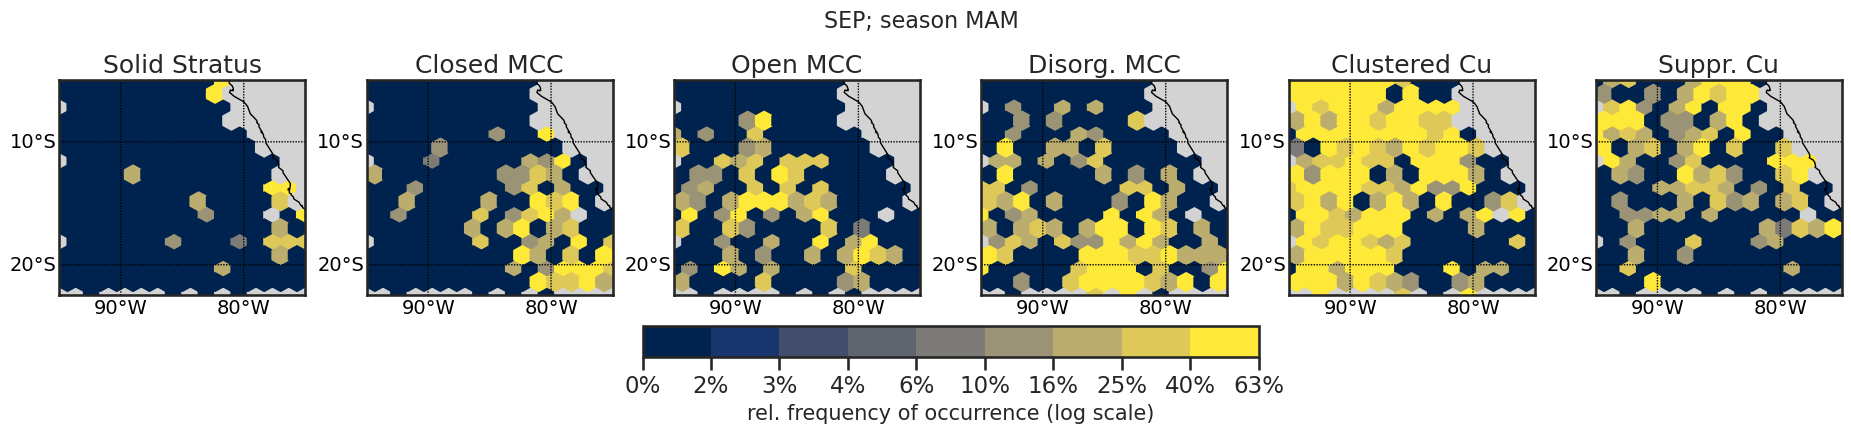

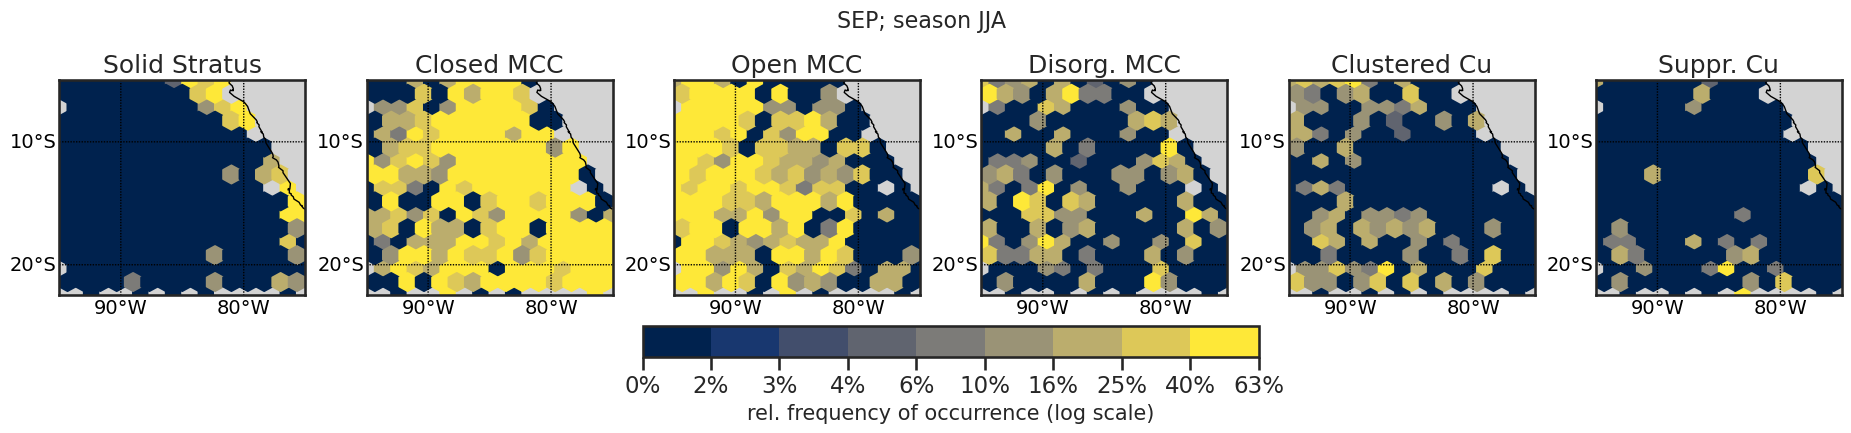

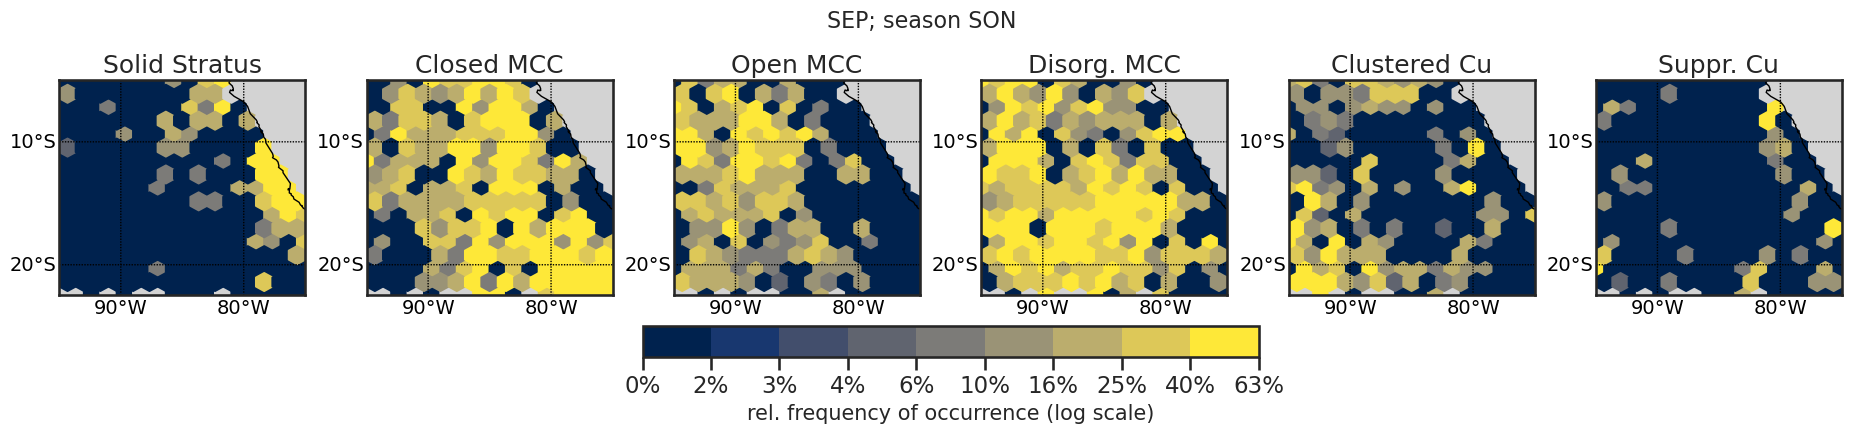

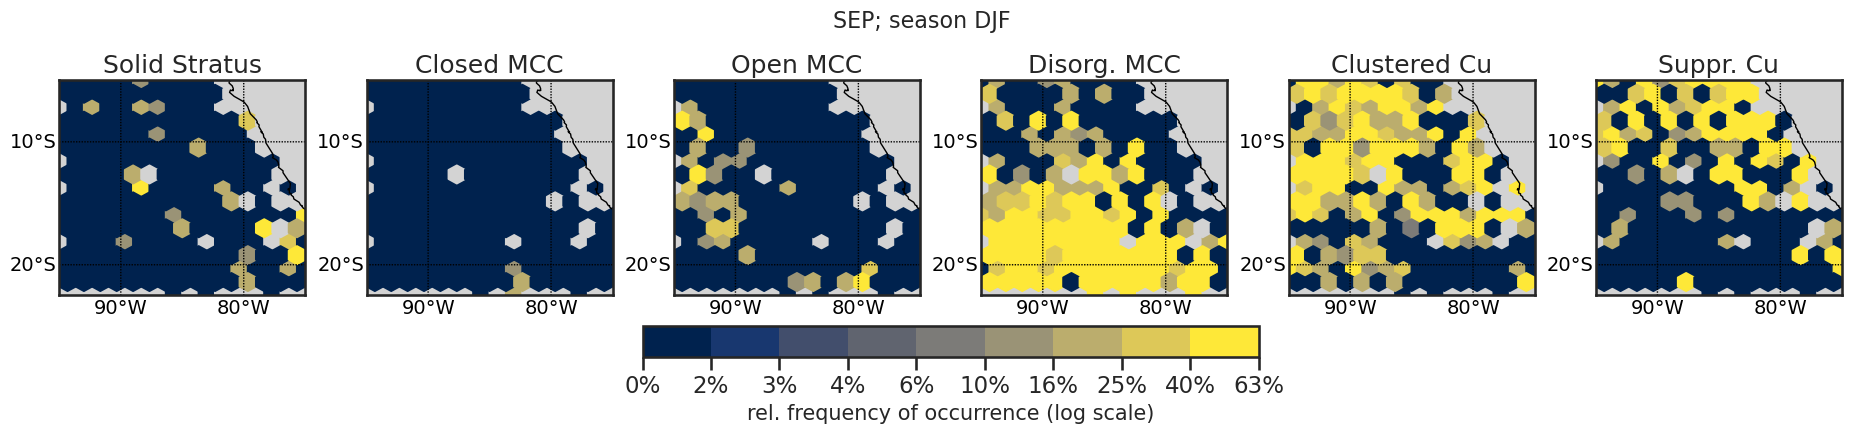

In [225]:
#ticks = np.linspace(0, 1, 11)[:-1]
#bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)
#lnorm = colors.LogNorm(vmin=0.01, vmax=0.7)
ticks = np.logspace(-2, 0, 11)[:-1]
ticks[0]=0
bnorm = colors.BoundaryNorm(boundaries=ticks, ncolors=256)

for j in range(4):
    for season in ['MAM', 'JJA', 'SON', 'DJF']:
        stratus_region_order = [2, 3, 0, 1]
        sr = stratus_region_order[j]
        stratus_region_names = {0:'SEA', 1:'NEA', 2:'SEP', 3:'NEP'}
        llr = stratus_regions[stratus_region_names[sr]]

        if season == 'JJA':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([6,7,8]))]
        elif season == 'MAM':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([3,4,5]))]
        elif season == 'SON':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([9,10,11]))]
        elif season == 'DJF':
            dffil_season = dffil[(dffil.time_mid.dt.month.isin([12,1,2]))]

        gridsize = 15
        fig, ax = plt.subplots()
        b = bmap(ax=ax, llr=llr)
        plot_df = dffil_season[(dffil_season.stratus_region_index == sr)]
        image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
        all_counts = image.get_array()+1
        plt.close()

        fig, axs = plt.subplots(ncols=6, nrows=1, figsize=(23, 4), sharex=True, sharey=True)
        plt.suptitle(f'{stratus_region_names[sr]}; season {season}', fontsize=16)
        axn = axs.flatten()
        for i, ax in enumerate(axn):
            plot_df = dffil_season[(dffil_season.stratus_region_index == sr) & (dffil_season['cats'] == i)]

            b = bmap(ax=ax, llr=llr, merspace=10, parspace=10)
            image = b.hexbin(plot_df['lon_mid'], plot_df['lat_mid'], gridsize=gridsize, extent=(*llr['lon'], *llr['lat']), norm=bnorm, cmap='cividis')
            normed_counts = image.get_array()/all_counts
            normed_counts[all_counts<2] = -1
            
            image.set_array(normed_counts)
            image.cmap.set_under('lightgrey')
            ax.set_title(cats_names[i])

        plt.subplots_adjust(hspace=0.5, wspace=0.25)
        cb = plt.colorbar(image, ax=axn, ticks=ticks, orientation='horizontal', pad=0.1, fraction=0.1)
        cb.set_ticklabels([f"{i:0.0%}" for i in ticks])
        cb.set_label("rel. frequency of occurrence (log scale)", fontsize=15)
        plt.show()
    break

## mesoscale structure

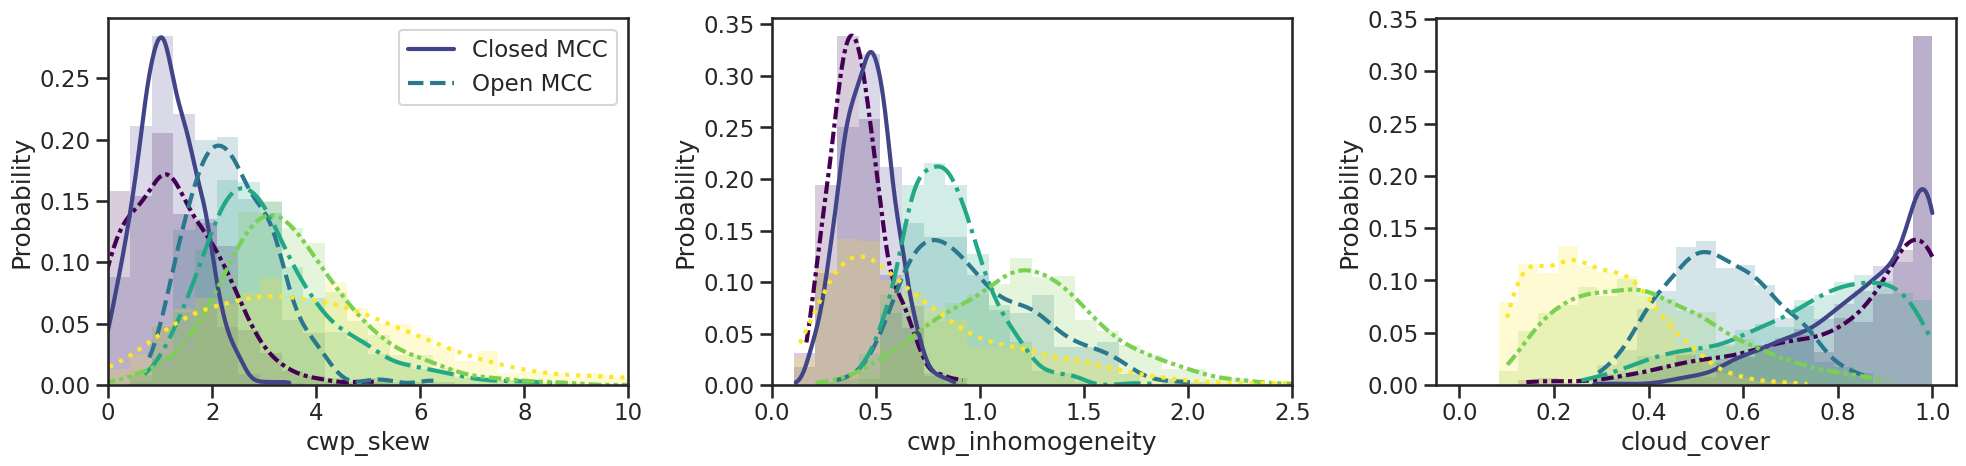

In [319]:
cloud_regime = 'cats'
# check how the clusters relate to the M-COP variables
fig, ax = plt.subplots(1,3, figsize=(20, 5))
for i in [0,1,2,3,4,5]: #6

    histplot_with_style(i, ax[0], dffil, 'cwp_skew', np.linspace(0,10,25))
    histplot_with_style(i, ax[1], dffil, 'cwp_inhomogeneity', np.linspace(0,2.5,25))
    histplot_with_style(i, ax[2], dffil, 'cloud_cover', np.linspace(0,1,25))

ax[0].legend(handles=legend_elements)
ax[0].set_xlim(0,10)
ax[1].set_xlim(0,2.5)
fig.tight_layout()

## vertical structure

### histograms

In [320]:
dffil['H'] = (np.abs(dffil['cth'] - dffil['cbh']) + 1) * 100 # transform to meters
dffil['daytime'] = dffil['daytime'].astype(int)

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

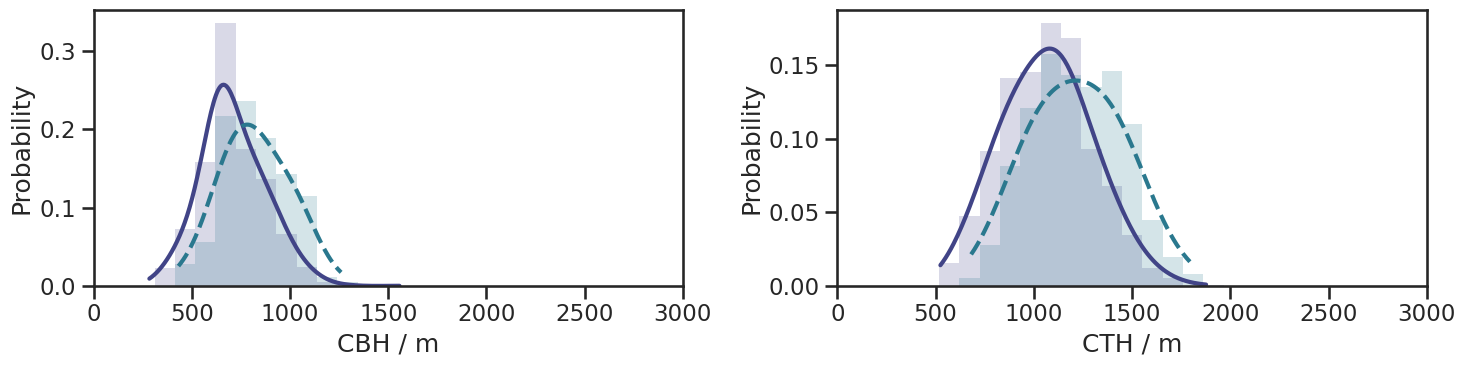

In [321]:
fig, ax = plt.subplots(1,2, figsize=(15, 4))
for i in [1,2]: #[0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'cbh_m', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1], dffil, 'cth_m', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
ax[0].set_xlim(0,3000)
ax[1].set_xlim(0,3000)
ax[0].set_xlabel('CBH / m')
ax[1].set_xlabel('CTH / m')
#ax[0].legend(handles=legend_elements)
fig.tight_layout()

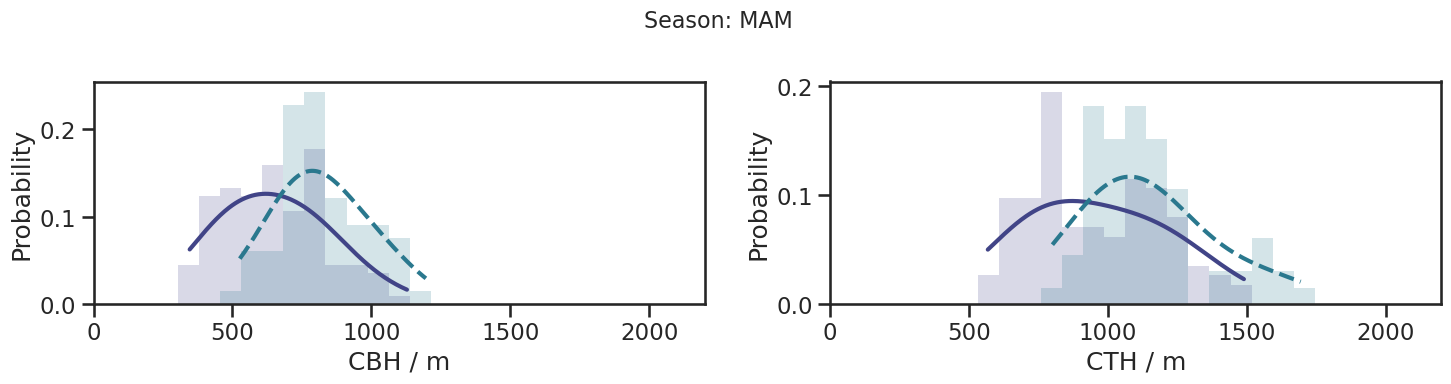

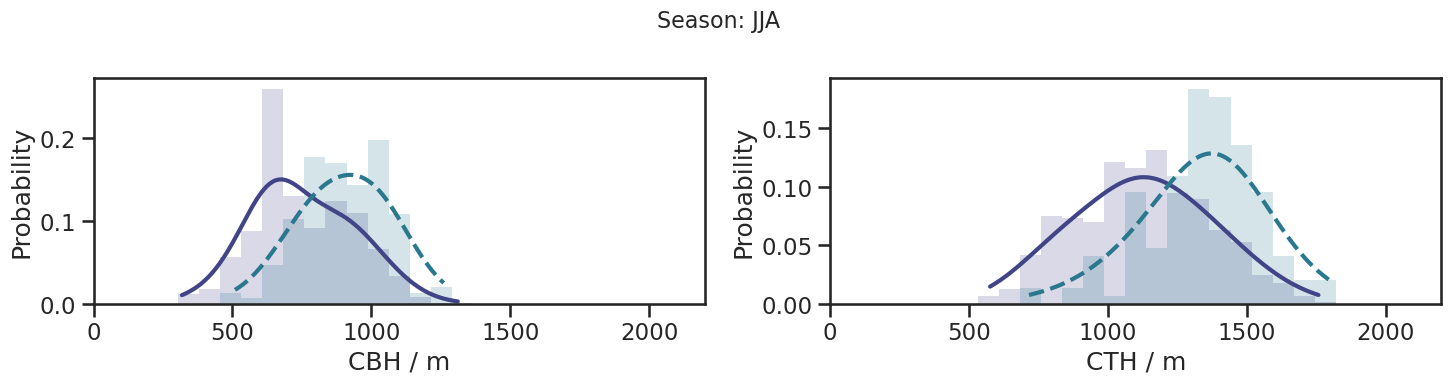

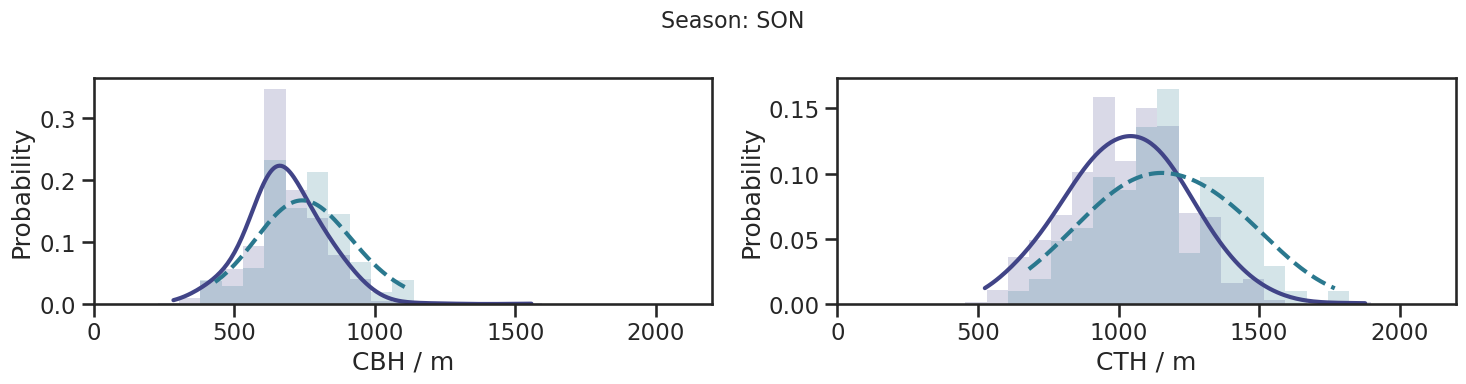

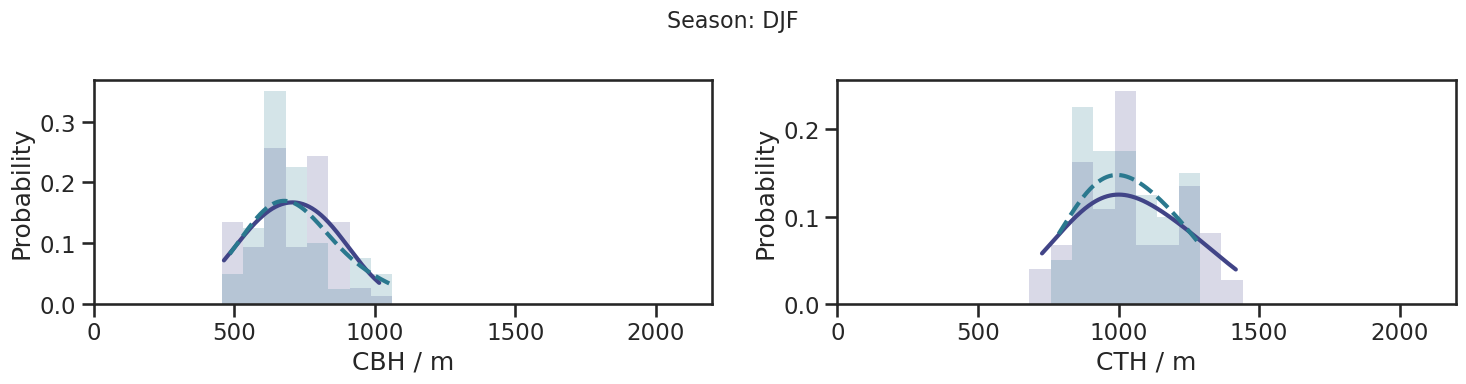

In [322]:
for season in ['MAM', 'JJA', 'SON', 'DJF']:
    if season == 'JJA':
        dffil_season = dffil[(dffil.time_mid.dt.month.isin([6,7,8]))]
    elif season == 'MAM':
        dffil_season = dffil[(dffil.time_mid.dt.month.isin([3,4,5]))]
    elif season == 'SON':
        dffil_season = dffil[(dffil.time_mid.dt.month.isin([9,10,11]))]
    elif season == 'DJF':
        dffil_season = dffil[(dffil.time_mid.dt.month.isin([12,1,2]))]

    fig, ax = plt.subplots(1,2, figsize=(15, 4))
    fig.suptitle(f'Season: {season}', fontsize=16)
    for i in [1,2]: #[0,1,2,3,4,5]: 
        histplot_with_style(i, ax[0], dffil_season, 'cbh_m', np.linspace(0,2200,30), kde_kws={'bw_adjust':2})
        histplot_with_style(i, ax[1], dffil_season, 'cth_m', np.linspace(0,2200,30), kde_kws={'bw_adjust':2})
    ax[0].set_xlim(0,2200)
    ax[1].set_xlim(0,2200)
    ax[0].set_xlabel('CBH / m')
    ax[1].set_xlabel('CTH / m')
    #ax[0].legend(handles=legend_elements)
    fig.tight_layout()
    plt.show()  

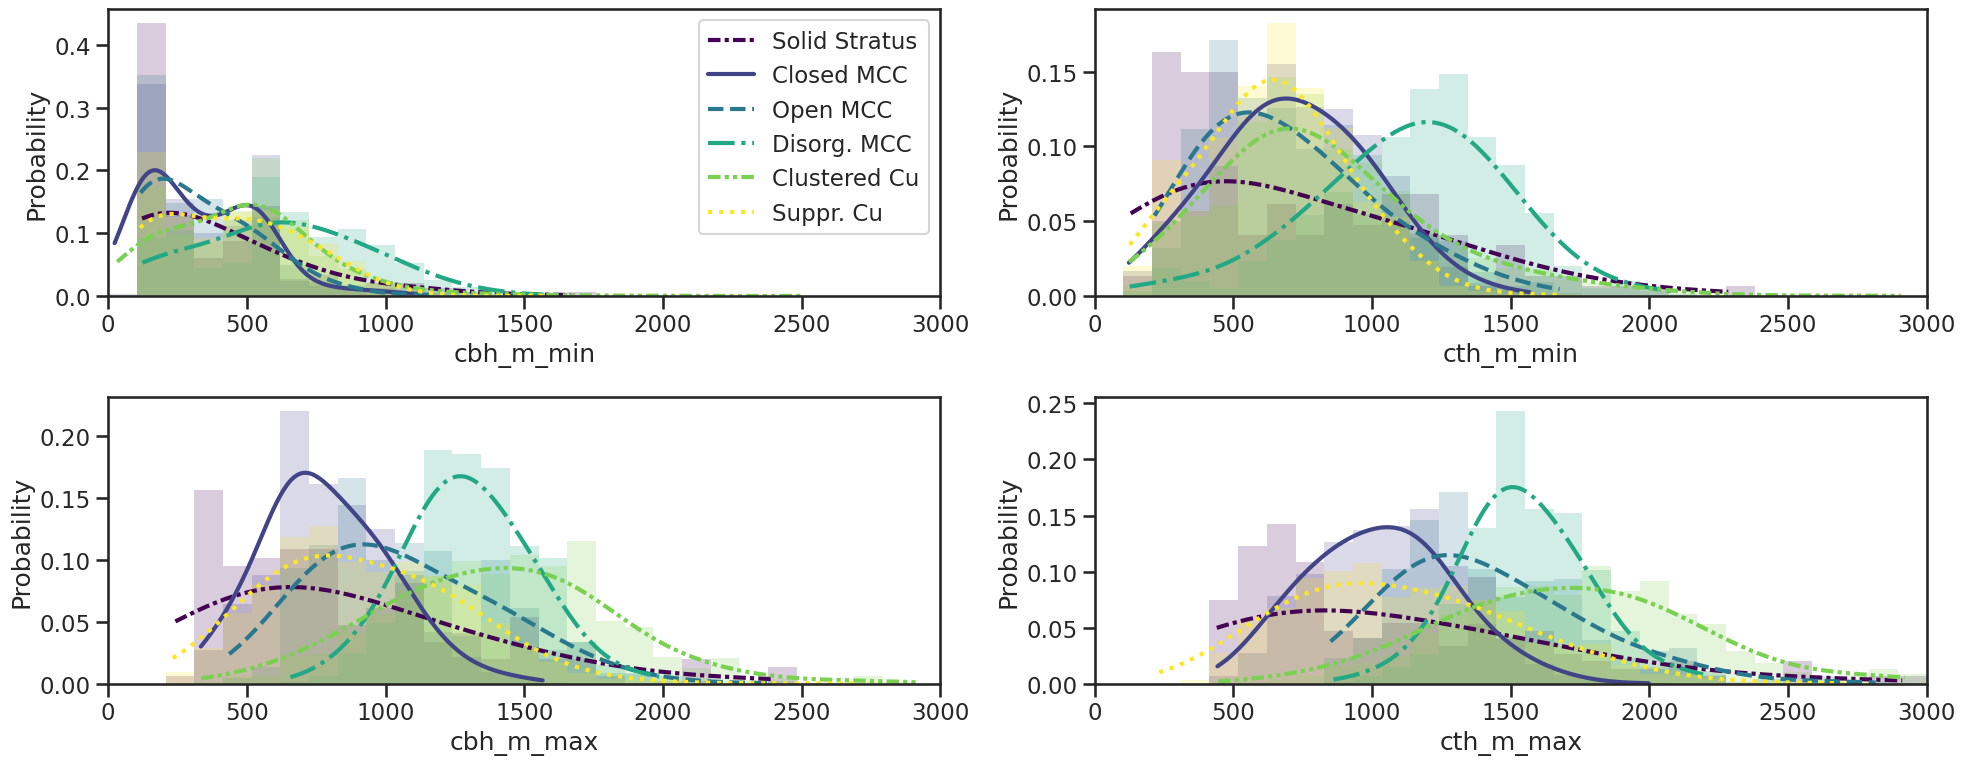

In [286]:
fig, ax = plt.subplots(2,2, figsize=(20, 8))
for i in [0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0,0], dffil, 'cbh_m_min', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1,0], dffil, 'cbh_m_max', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[0,1], dffil, 'cth_m_min', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})
    histplot_with_style(i, ax[1,1], dffil, 'cth_m_max', np.linspace(0,3000,30), kde_kws={'bw_adjust':2})

ax[0,0].set_xlim(0,3000)
ax[0,1].set_xlim(0,3000)
ax[1,0].set_xlim(0,3000)
ax[1,1].set_xlim(0,3000)
ax[0,0].legend(handles=legend_elements)
fig.tight_layout()

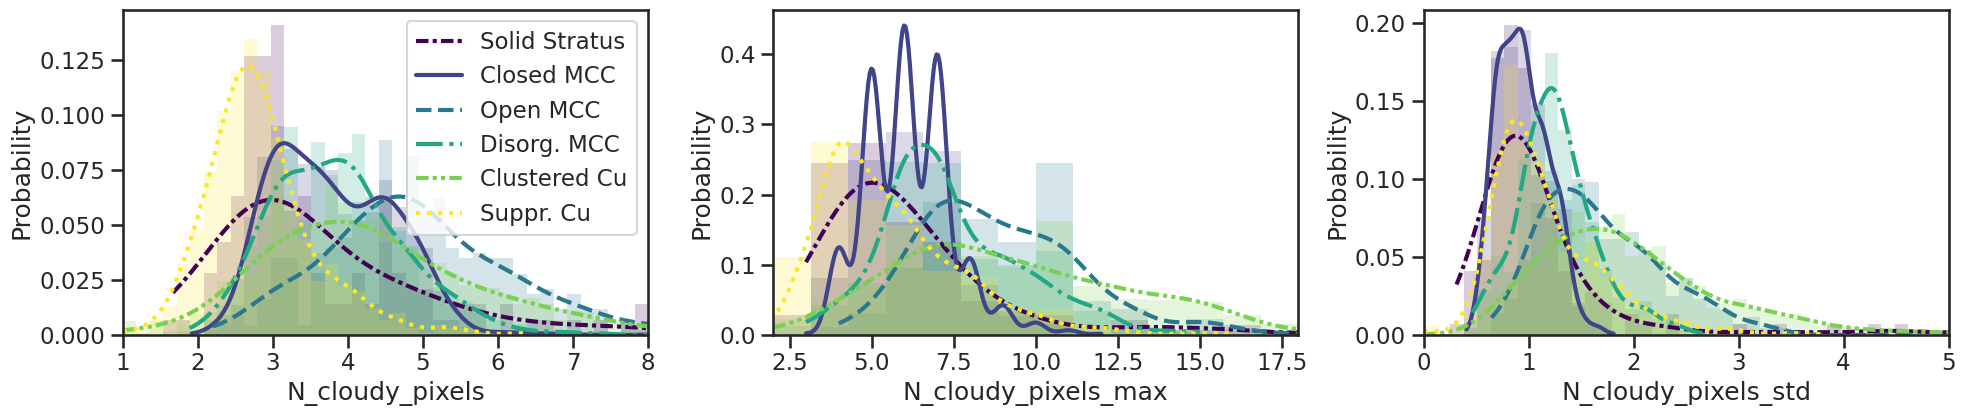

In [287]:
fig, ax = plt.subplots(1,3, figsize=(20, 4.5))
for i in [0,1,2,3,4,5]: 
    histplot_with_style(i, ax[0], dffil, 'N_cloudy_pixels', np.linspace(1,8,40))
    histplot_with_style(i, ax[1], dffil, 'N_cloudy_pixels_max', np.linspace(2,18,15))
    histplot_with_style(i, ax[2], dffil, 'N_cloudy_pixels_std', np.linspace(0,5,40))

ax[0].set_xlim(1,8)
ax[1].set_xlim(2,18)
ax[2].set_xlim(0,5)
ax[0].legend(handles=legend_elements)
fig.tight_layout()

In [239]:
dffil[(dffil['cats'] == 2) & (dffil.N_cloudy_pixels_max >= 12)].orbit.unique()

array(['01087E', '01304E', '01849E', '02565E', '02596E', '02907E',
       '03265E', '04214E', '04650E', '05101E', '05241E', '05272E',
       '05288E', '05459E', '05630E', '05646E', '05677E', '05708E',
       '05786E', '05817E', '05910E', '05926E', '05941E', '05957E',
       '05988E', '06066E', '06175E', '06315E', '06346E', '06377E',
       '06408E', '06548E', '06579E', '06844E', '06984E', '07015E',
       '07217E', '07233E', '07373E', '07591E', '07762E', '07793E'],
      dtype=object)

## microphysics

### rain

In [324]:
dffil['rwp'] = dffil['rwp'] * 1e3 # transform to g/m2
dffil['rwp_subcloud'] = dffil['rwp_subcloud'] * 1e3 # transform to g/m2
dffil['rwp_std'] = dffil['rwp_std'] * 1e3 # transform to g/m2

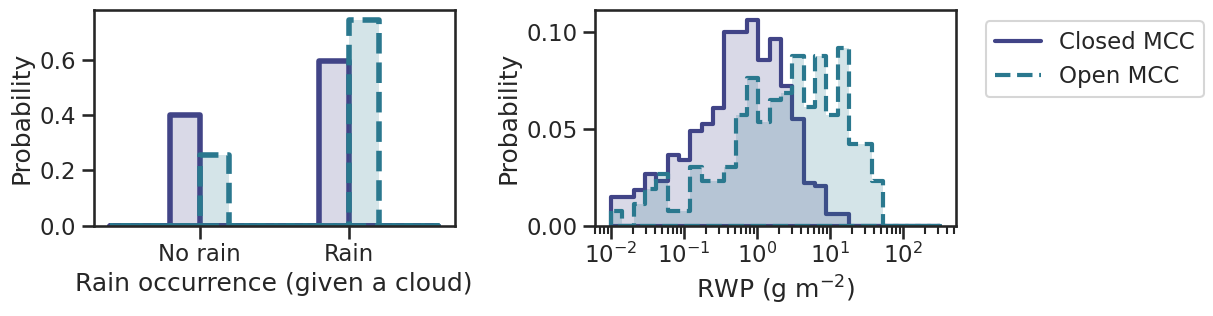

In [325]:
cats = [1,2]

fig, ax = plt.subplots(1,2, figsize=(10, 3.5))
for j,i in enumerate(cats):
    sns.histplot(ax=ax[0], x=(dffil[dffil['cats'] == i]['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', color=catcolors[i], lw=4, ls=line_styles[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i) & (dffil['rwp']>0)]['rwp'], bins=np.logspace(-2,2.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])


ax[1].set_xscale('log')
ax[1].set_xlabel('RWP (g m$^{-2}$)')

ax[0].set_xticks([0.1,1.1])
ax[0].set_xticklabels(['No rain', 'Rain'])
ax[0].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()

legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
ax[1].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left')

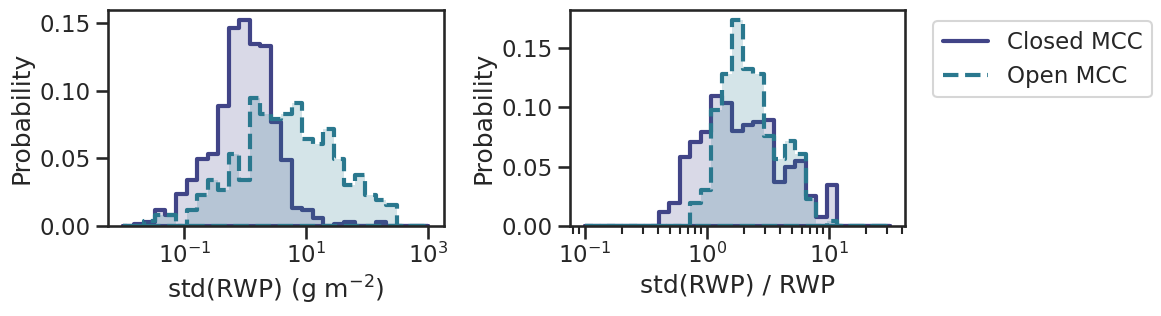

In [326]:
cats = [1,2]

fig, ax = plt.subplots(1,2, figsize=(12, 3.5))
for j,i in enumerate(cats):
    sns.histplot(
        ax=ax[0], x=dffil[(dffil['cats'] == i)]['rwp_std'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], x=dffil[(dffil['cats'] == i)]['rwp_std'] / dffil[(dffil['cats'] == i)]['rwp'], bins=np.logspace(-1,1.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[i],
        color=catcolors[i])


ax[0].set_xscale('log')
ax[0].set_xlabel('std(RWP) (g m$^{-2}$)')
ax[1].set_xscale('log')
ax[1].set_xlabel('std(RWP) / RWP')

legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
ax[1].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left')
fig.tight_layout()

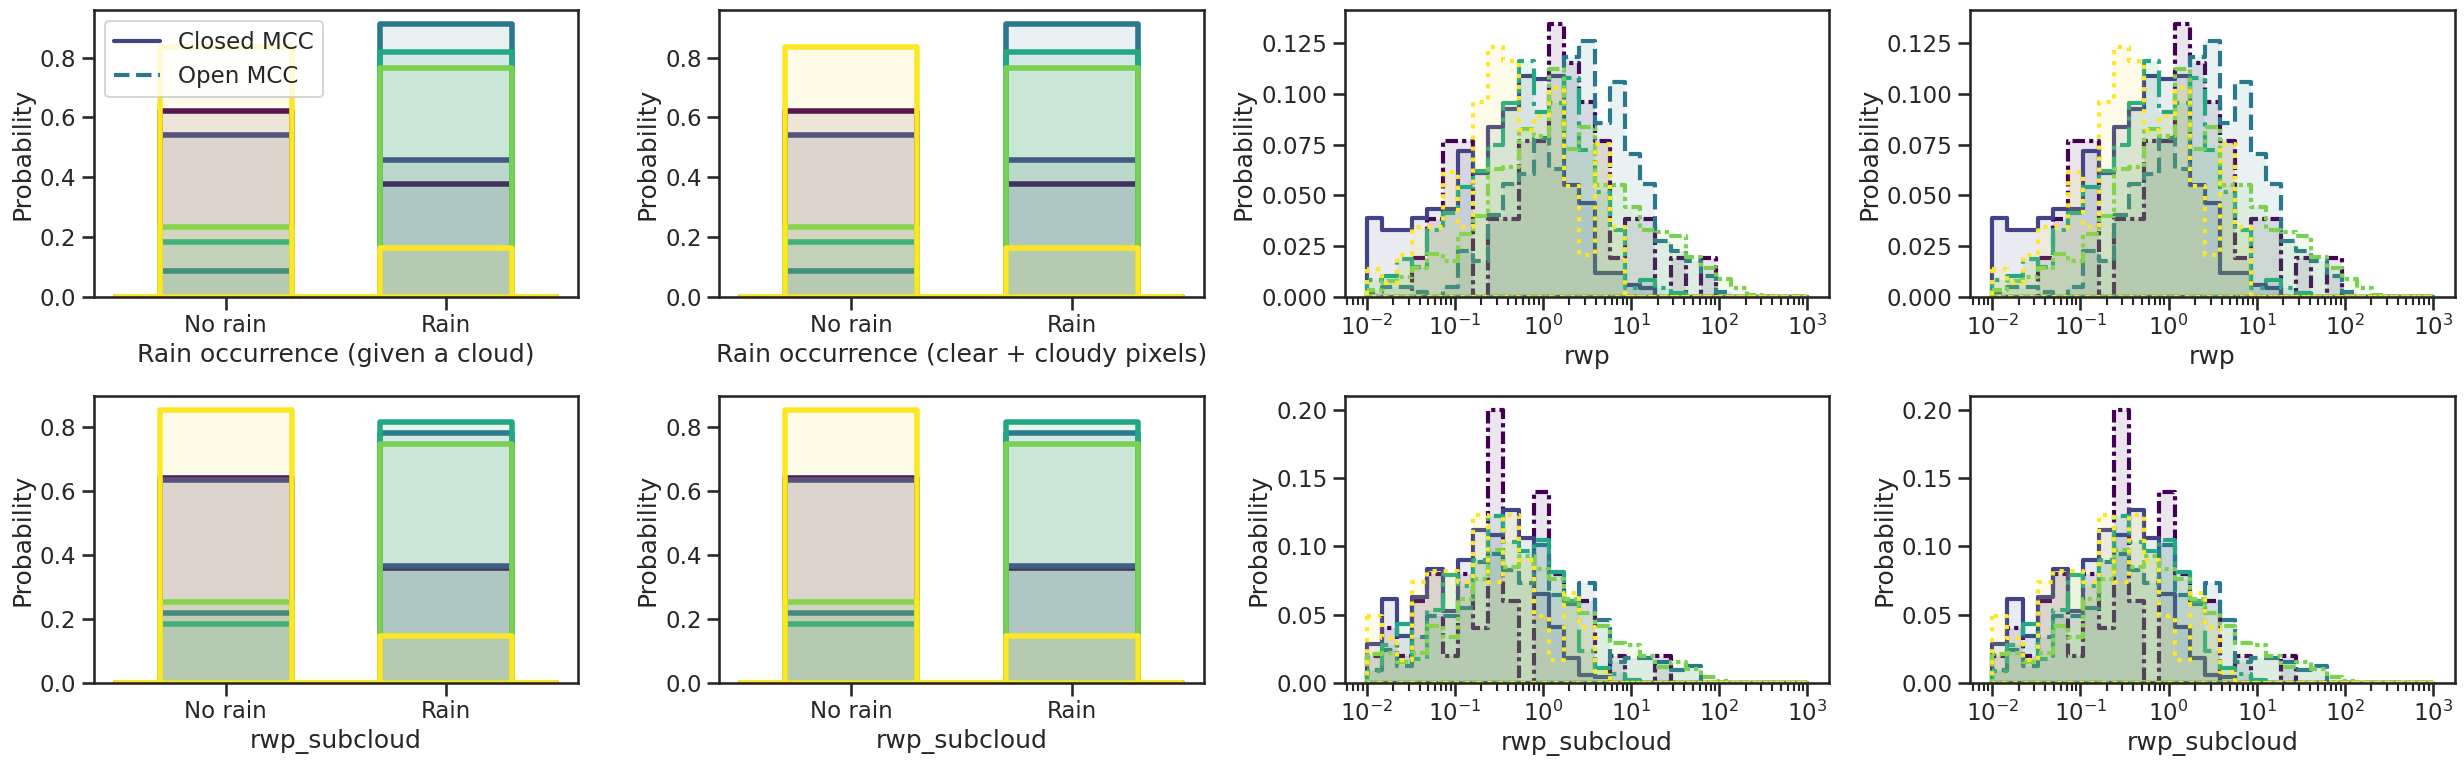

In [291]:
fig, ax = plt.subplots(2,4, figsize=(25, 8))
for i in [0,1,2,3,4,5]: #6
    sns.histplot(ax=ax[0,0], x=(dffil[dffil['cats'] == i]['rwp'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(ax=ax[0,1], x=(dffil[dffil['cats'] == i]['rwp'].fillna(0)>0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(
        ax=ax[0,2], x=dffil[dffil['cats'] == i]['rwp'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[0,3], x=dffil[(dffil['cats'] == i) & (dffil['rwp']>0)]['rwp'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    
    sns.histplot(ax=ax[1,0], x=(dffil[dffil['cats'] == i]['rwp_subcloud'] > 0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(ax=ax[1,1], x=(dffil[dffil['cats'] == i]['rwp_subcloud'].fillna(0)>0), bins=[-0.5,-0.3,0.3,0.7,1.3,1.5], element='step', alpha=0.1, stat='probability', color=catcolors[i], lw=4)
    sns.histplot(
        ax=ax[1,2], x=dffil[dffil['cats'] == i]['rwp_subcloud'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1,3], x=dffil[(dffil['cats'] == i) & (dffil['rwp_subcloud']>0)]['rwp_subcloud'], bins=np.logspace(-2,3,30),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])

ax[0,0].legend(handles=legend_elements)
for a in [ax[0,2], ax[0,3], ax[1,2], ax[1,3]]:
    a.set_xscale('log')

for a in [ax[0,0], ax[0,1], ax[1,0], ax[1,1]]:
    a.set_xticks([0,1])
    a.set_xticklabels(['No rain', 'Rain'])
ax[0,0].set_xlabel('Rain occurrence (given a cloud)')
ax[0,1].set_xlabel('Rain occurrence (clear + cloudy pixels)')
fig.tight_layout()

### LWP, Nd, ER

In [327]:
dffil['Nd'] = dffil['Nd'] * 1e-6 # transform to cm-3
dffil['lwp'] = dffil['lwp'] * 1e3 # transform to g/m2
dffil['lwp_std'] = dffil['lwp_std'] * 1e3 # transform to g/m2

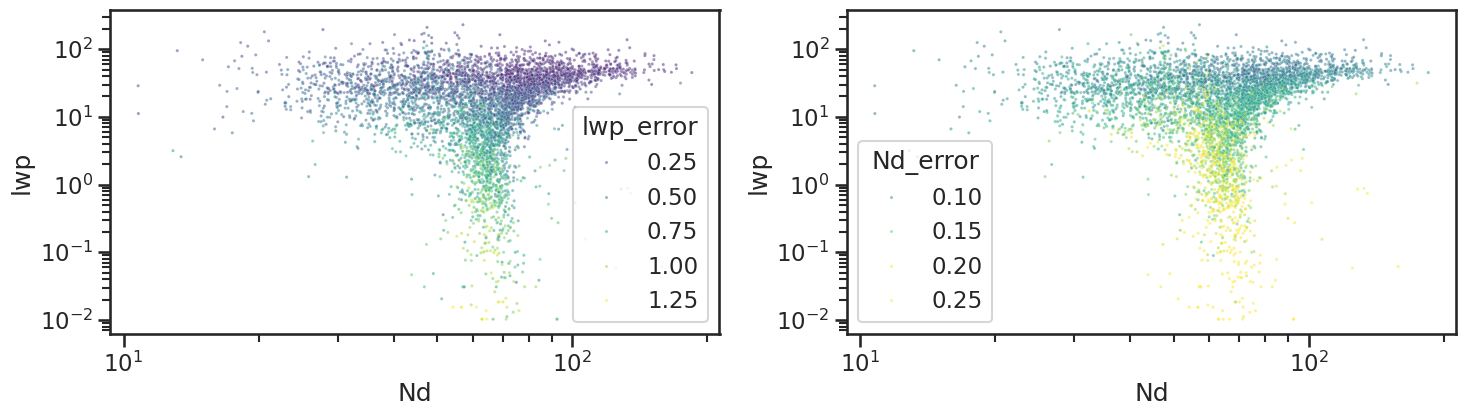

In [293]:
fig, ax = plt.subplots(1,2, figsize=(15,4.5))
sns.scatterplot(ax=ax[0], data=dffil, x='Nd', y='lwp', hue='lwp_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,1.2))
sns.scatterplot(ax=ax[1], data=dffil, x='Nd', y='lwp', hue='Nd_error', palette='viridis', alpha=0.5, s=5, hue_norm=(0,0.2))
for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')
fig.tight_layout()

Text(0.5, 0, 'Nd error')

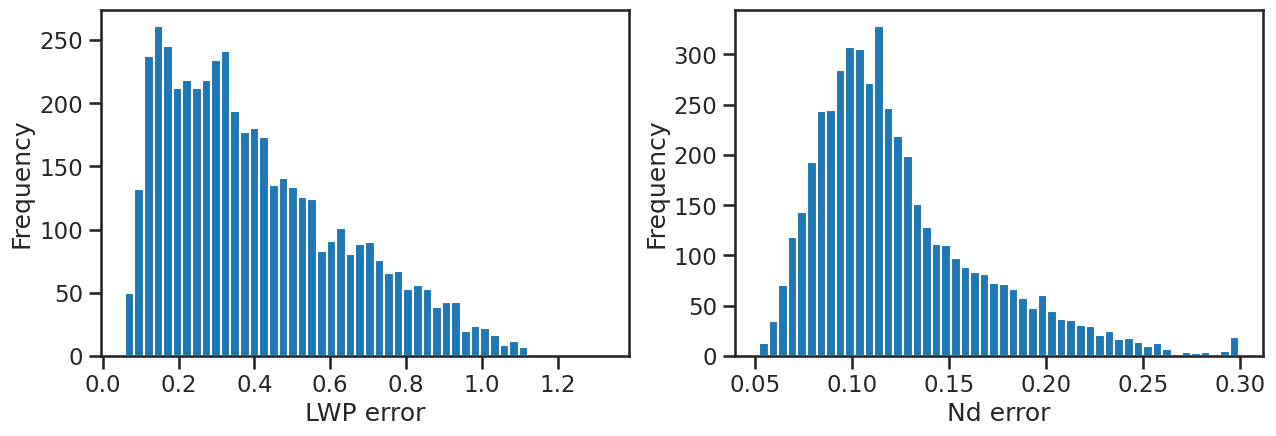

In [294]:
fig, ax = plt.subplots(1,2, figsize=(15,4.5))
dffil.lwp_error.plot.hist(ax=ax[0], bins=50)
dffil.Nd_error.plot.hist(ax=ax[1], bins=50)
ax[0].set_xlabel('LWP error')
ax[1].set_xlabel('Nd error')

In [328]:
dffil['lwp_fil'] = dffil['lwp'].where((dffil.lwp_error <= 0.6) & (dffil.Nd_error <= 0.15))
dffil['Nd_fil'] = dffil['Nd'].where((dffil.lwp_error <= 0.6) & (dffil.Nd_error <= 0.15))
dffil['ER_fil'] = dffil['ER'].where((dffil.lwp_error <= 0.6) & (dffil.Nd_error <= 0.15))

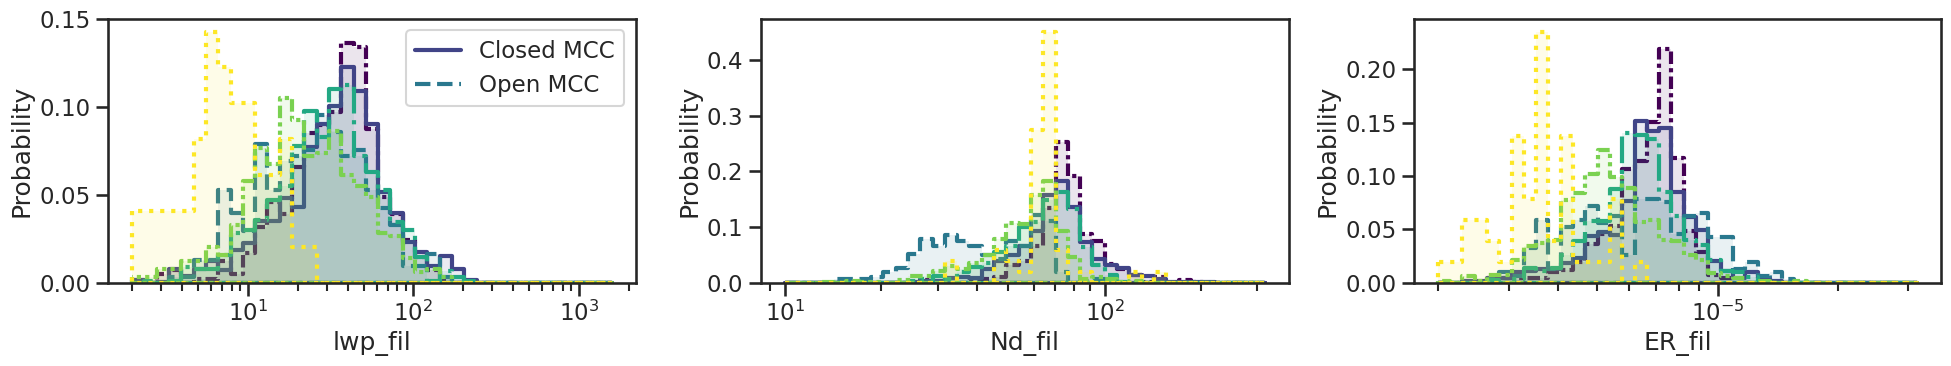

In [329]:
fig, ax = plt.subplots(1,3, figsize=(20, 4))
for i in [0,1,2,3,4,5]: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_fil', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_fil', bins=np.logspace(1,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_fil', bins=np.logspace(-5.7,-4.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
ax[0].legend(handles=legend_elements)
fig.tight_layout()

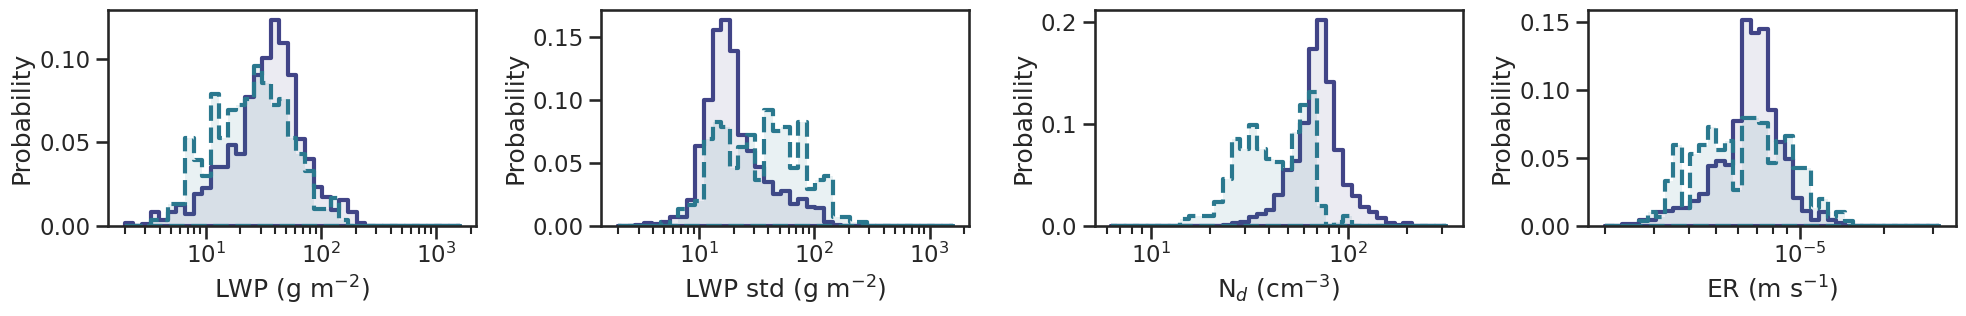

In [330]:
cats = [1,2]

fig, ax = plt.subplots(1,4, figsize=(20, 3.5))
for i in cats: 
    sns.histplot(
        ax=ax[0], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_fil', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[1], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='lwp_std', bins=np.logspace(0.3,3.2,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[2], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='Nd_fil', bins=np.logspace(0.8,2.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
    sns.histplot(
        ax=ax[3], data=dffil[dffil.lwp_fil > 0][dffil['cats'] == i], x='ER_fil', bins=np.logspace(-5.7,-4.5,40),
        element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
        color=catcolors[i])
for a in ax.flatten():
    a.set_xscale('log')
legend_elements = [
    Line2D([0], [0], color=catcolors[i], lw=3, linestyle=line_styles[i], label=cats_names[i])
    for i in cats
]
#ax[0].legend(handles=legend_elements)
ax[0].set_xlabel('LWP (g m$^{-2}$)')
ax[1].set_xlabel('LWP std (g m$^{-2}$)')
ax[2].set_xlabel('N$_d$ (cm$^{-3}$)')
ax[3].set_xlabel('ER (m s$^{-1}$)')
fig.tight_layout()

0 0 0
0 1 0
0 2 0
0 3 0
0 4 0
0 5 0
1 0 0
1 1 0
1 2 0
1 3 0
1 4 0
1 5 0
2 5 6
3 0 0
3 1 0
3 2 0
3 3 0
3 4 0
3 5 0


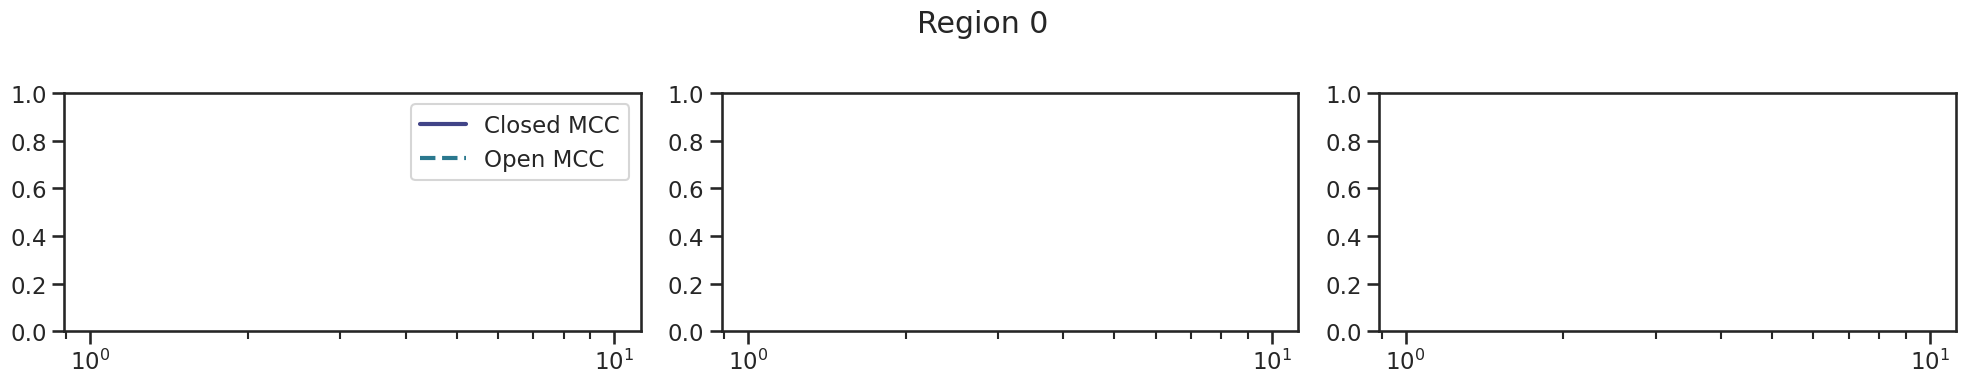

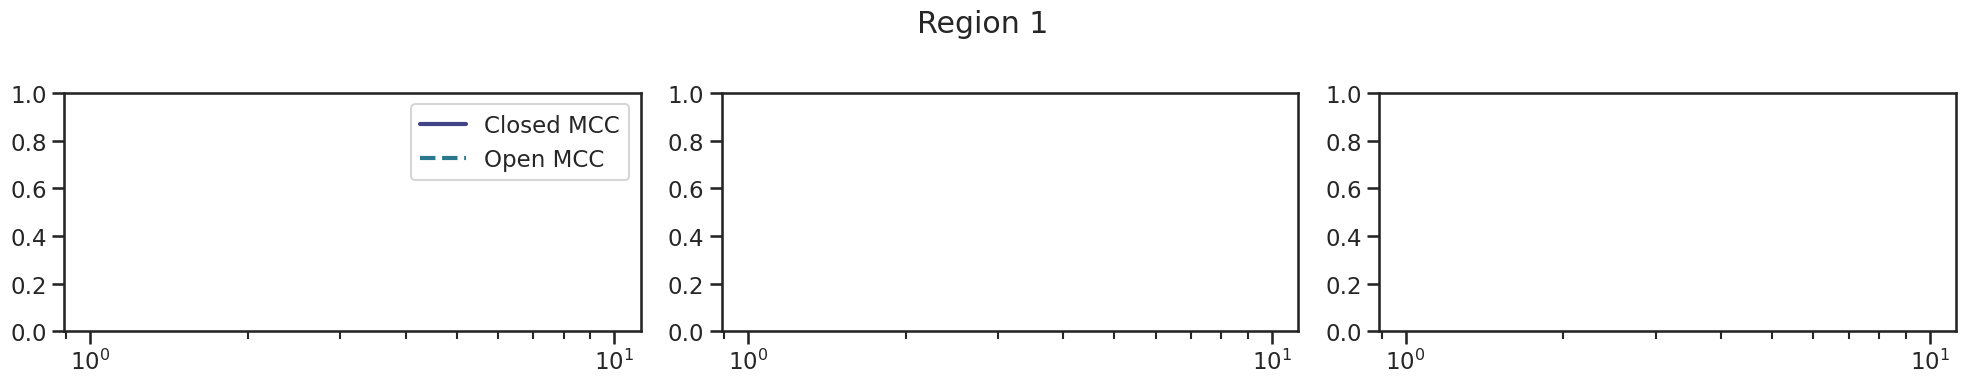

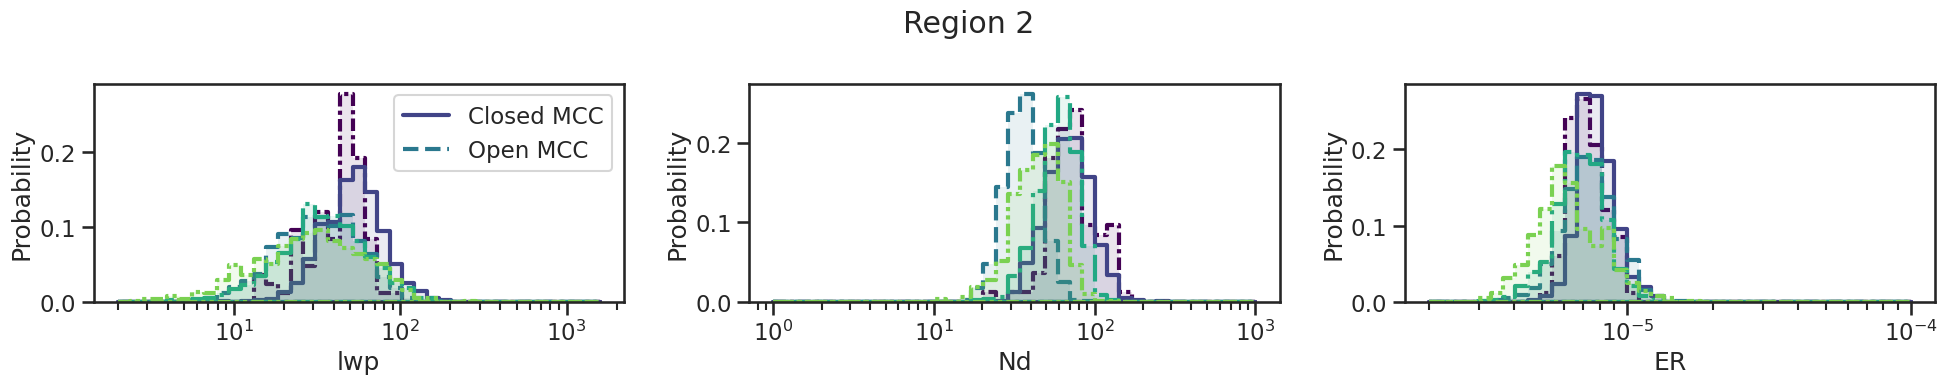

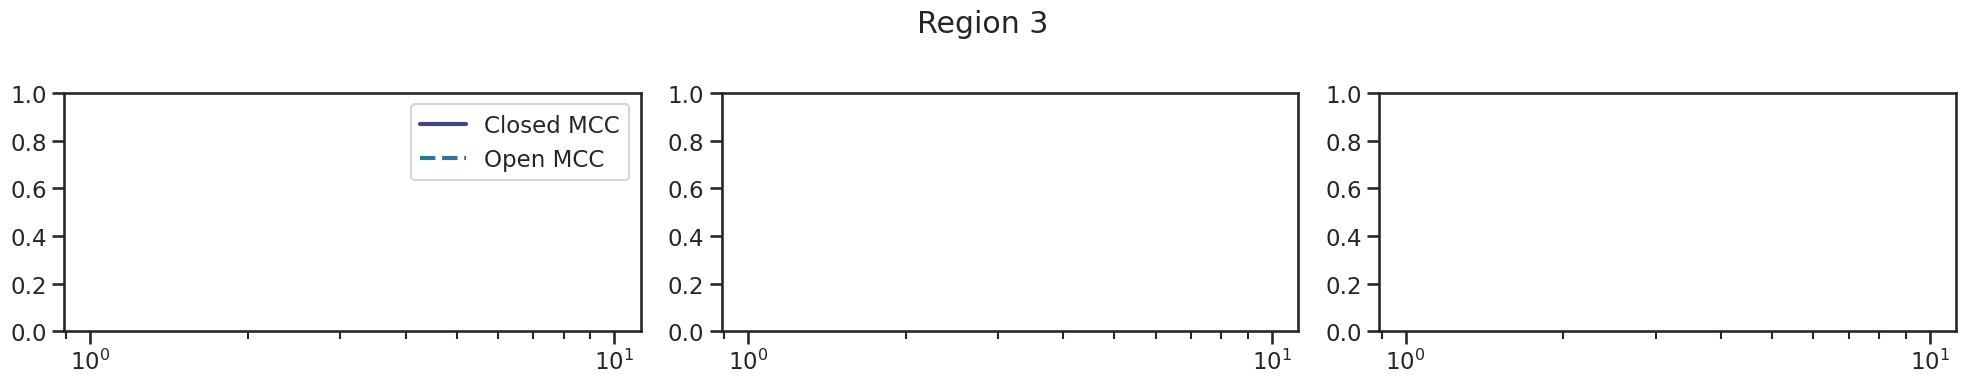

In [178]:
for reg in [0,1,2,3]:
    fig, ax = plt.subplots(1,3, figsize=(20, 4))
    fig.suptitle(f'Region {reg}')
    for i in [0,1,2,3,4,5]: 
        d = dffil[(dffil['cats'] == i) & (dffil.stratus_region_index == reg)].dropna()
        if len(d.groupby('scene_id')['cats'].mean()) < 10: # at least 10 scenes per category
            print(reg, i, len(d))
            continue
        sns.histplot(
            ax=ax[0], data=d, x='lwp', bins=np.logspace(0.3,3.2,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
        sns.histplot(
            ax=ax[1], data=d, x='Nd', bins=np.logspace(0,3,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
        sns.histplot(
            ax=ax[2], data=d, x='ER', bins=np.logspace(-5.7,-4,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles[i],
            color=catcolors[i])
    for a in ax.flatten():
        a.set_xscale('log')
    ax[0].legend(handles=legend_elements)
    fig.tight_layout()

0 0 0
1 0 0
3 0 0
0 1 0
1 1 0
3 1 0
0 2 0
1 2 0
3 2 0
0 3 0
1 3 0
3 3 0
0 4 0
1 4 0
3 4 0
0 5 0
1 5 0
2 5 6
3 5 0


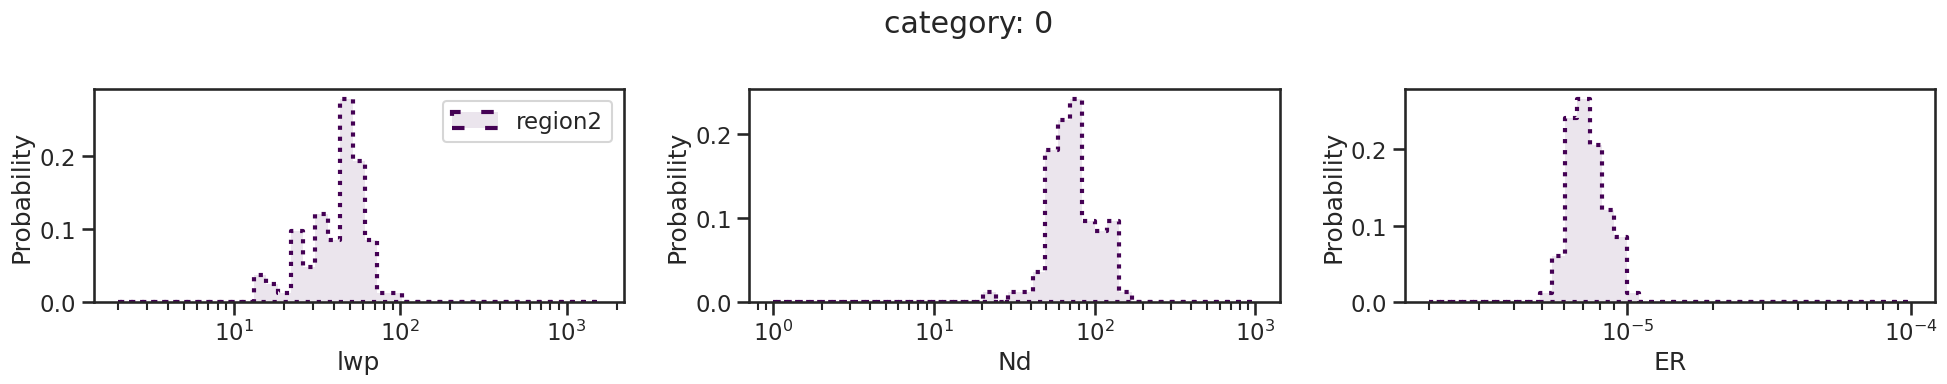

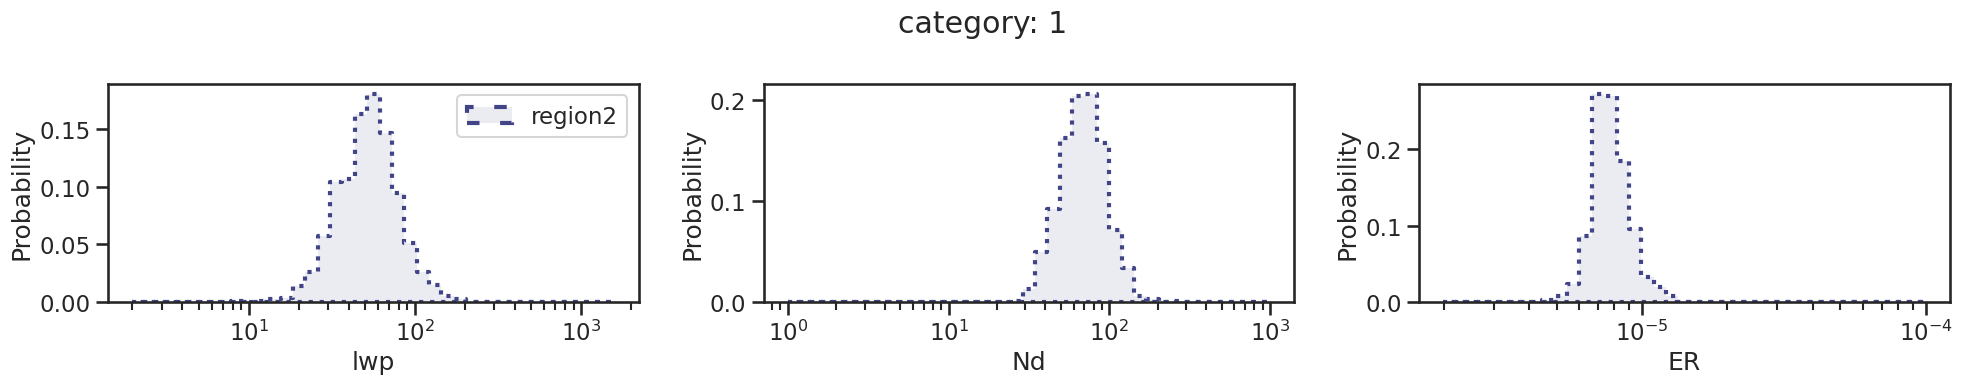

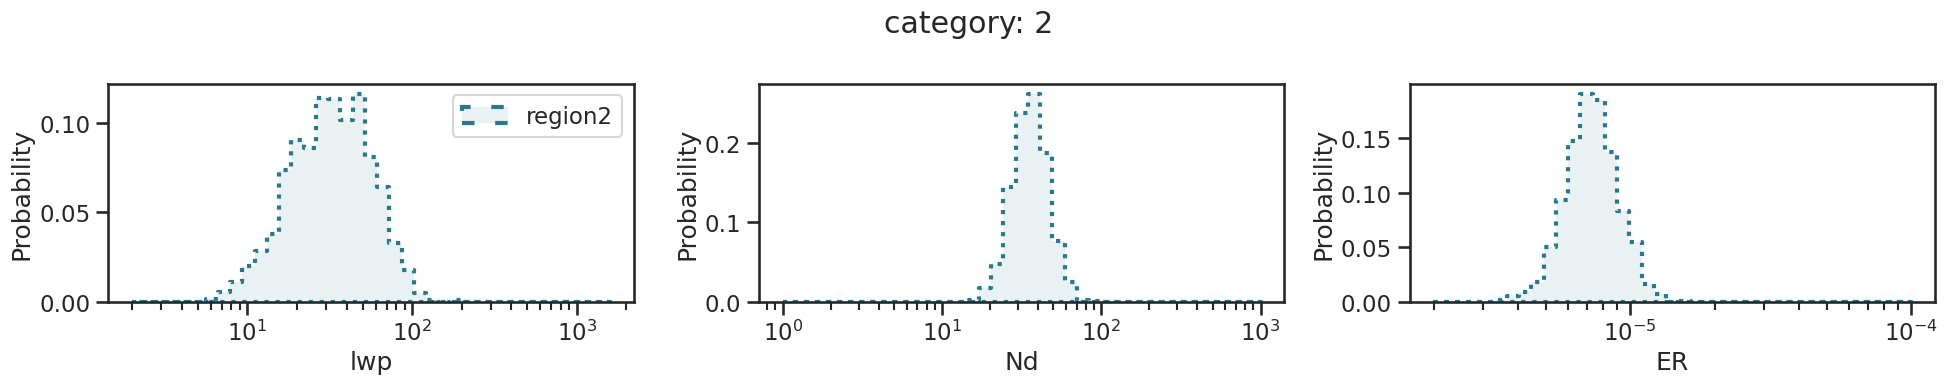

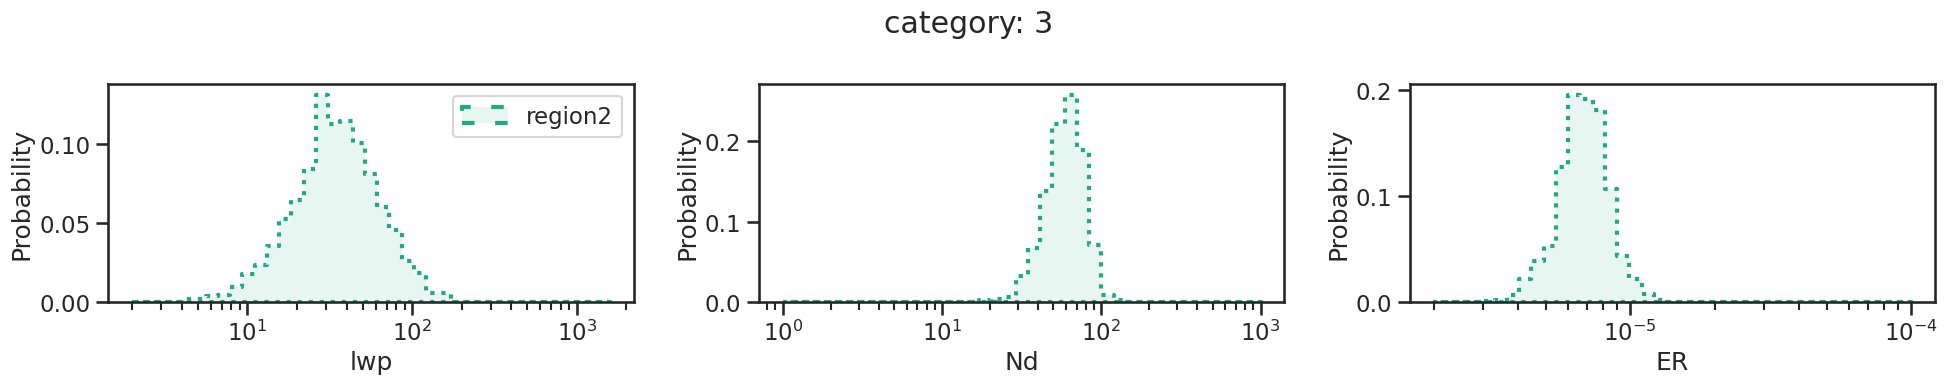

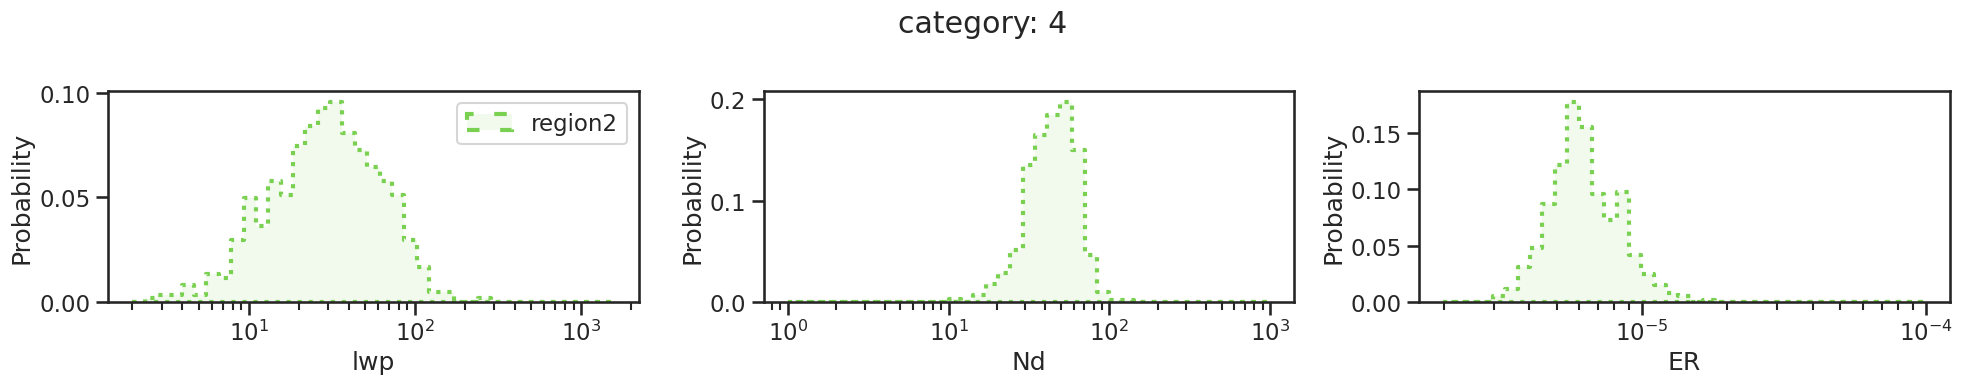

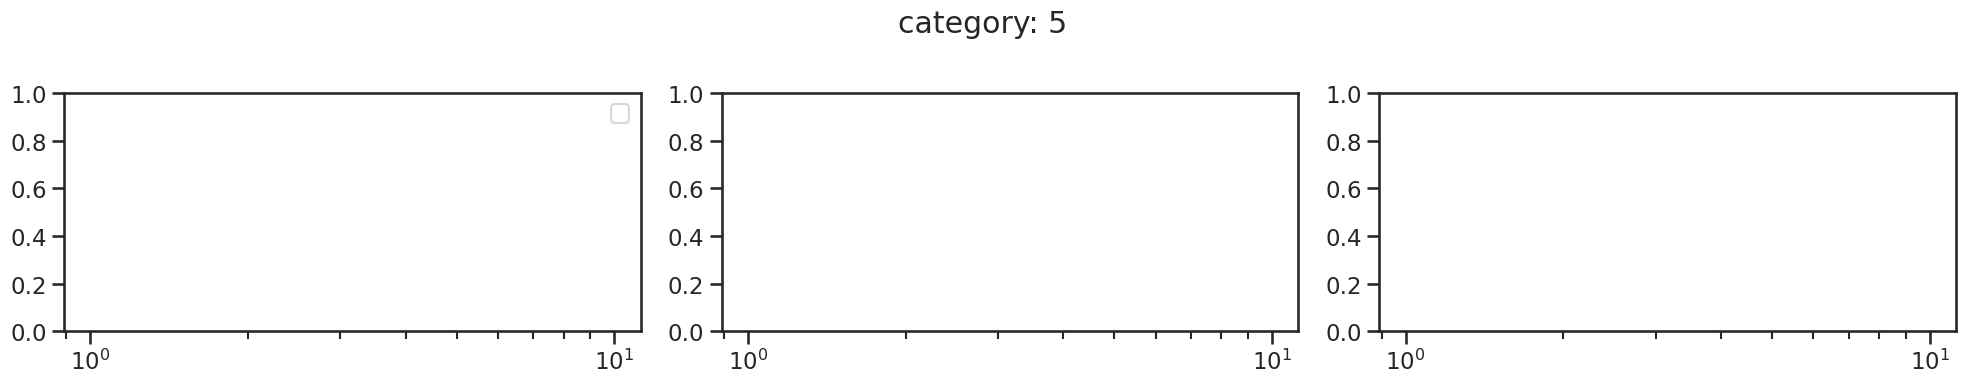

In [179]:
line_styles_region = ['solid', 'dashed', 'dotted', 'dashdot']

for i in [0,1,2,3,4,5]: 
    fig, ax = plt.subplots(1,3, figsize=(20, 4))
    fig.suptitle(f'category: {i}')
    for reg in [0,1,2,3]:
        d = dffil[(dffil['cats'] == i) & (dffil.stratus_region_index == reg)].dropna()
        if len(d.groupby('scene_id')['cats'].mean()) < 10: # at least 10 scenes per category
            print(reg, i, len(d))
            continue
        sns.histplot(
            ax=ax[0], data=d, x='lwp', bins=np.logspace(0.3,3.2,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i], label='region'+str(reg))
        sns.histplot(
            ax=ax[1], data=d, x='Nd', bins=np.logspace(0,3,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i])
        sns.histplot(
            ax=ax[2], data=d, x='ER', bins=np.logspace(-5.7,-4,40),
            element='step', stat='probability', fill=True, alpha=0.1, lw=3, ls=line_styles_region[reg],
            color=catcolors[i])
    for a in ax.flatten():
        a.set_xscale('log')
    ax[0].legend()
    fig.tight_layout()

## relationships: LWP, H, RWP

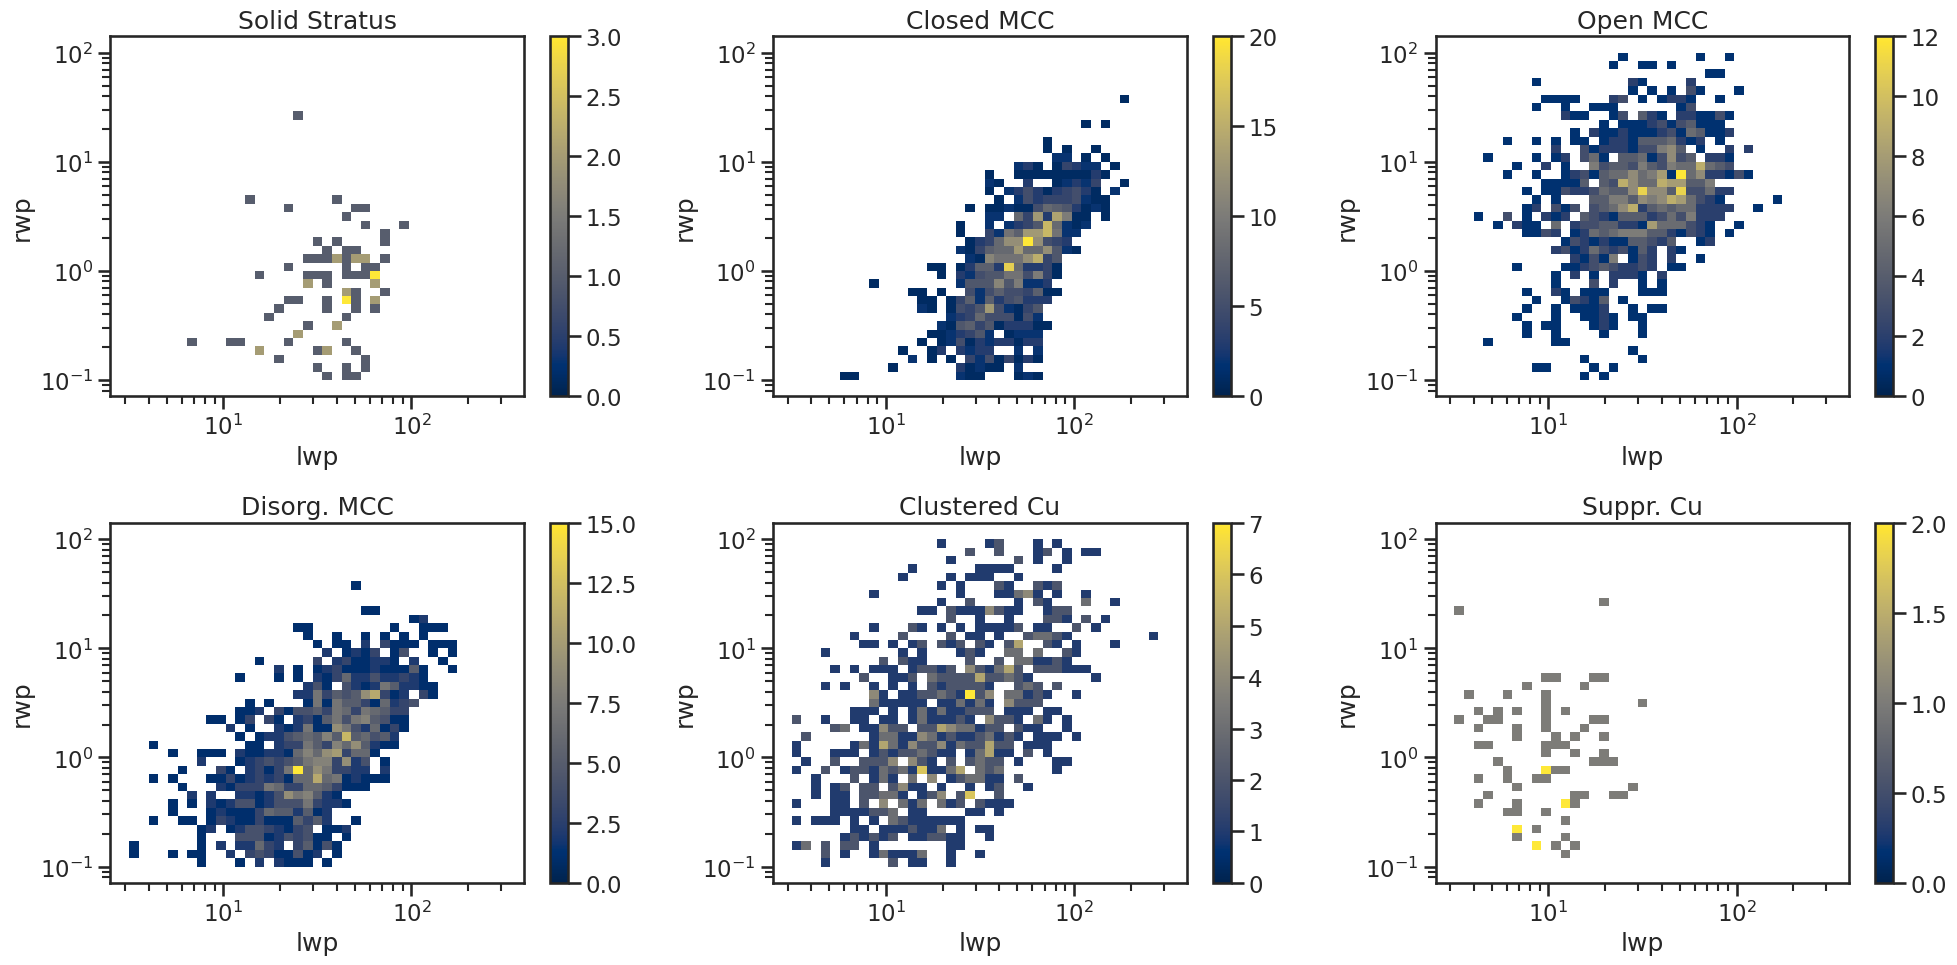

In [221]:
fig, axs = plt.subplots(2,3,figsize=(20,10))
for i in [0,1,2,3,4,5]:
    sns.histplot(ax=axs.flatten()[i], data=dffil[dffil.cats==i], x='lwp', y='rwp', bins=( np.logspace(0.5,2.5,40), np.logspace(-1,2,40)), cbar=True, cmap='cividis')
    xline = np.linspace(0,15,100)
    yline = (xline)**2 + 10
    #axs.flatten()[i].plot(xline, yline, color='black', lw=2)
    axs.flatten()[i].set_yscale('log')
    axs.flatten()[i].set_xscale('log')
    axs.flatten()[i].set_title(cats_names[i])
fig.tight_layout()

Text(0.5, 1.0, 'Mean RWP given LWP for different cloud categories')

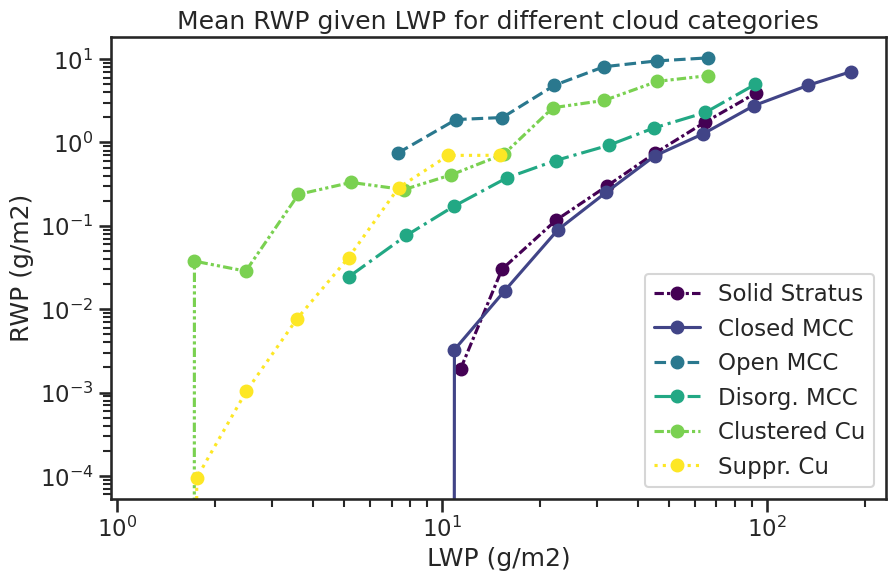

In [331]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for i in [0,1,2,3,4,5]:
    tmp = dffil[(dffil.cats==i)]
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP for different cloud categories')

In [ ]:
for sr in [0,1,2,3]:
    fig, axs = plt.subplots(1,1,figsize=(10,6))
    for i in [0,1,2,3,4,5]:
        tmp = dffil[(dffil.cats==i) & (dffil.stratus_region_index == sr)]
        rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
        rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
        rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 100, np.nan)
        rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])
        # rotate xlabels and round to 1 decimal place
        #plt.xticks(rotation=45)
    plt.ylim(-10,160)
    plt.xlabel('LWP (g/m2)')
    plt.ylabel('RWP (g/m2)')
    plt.title('Mean RWP given LWP for different cloud categories')

## archetypical profiles

In [ ]:
def add_profile(profile_arr, cbh_m, cth_m):
    # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
    for i in range(len(dfex)):
        cbh = cbh_m.values[i]
        cth = cth_m.values[i]
        if np.isnan(cbh) or np.isnan(cth):
            continue
        cbh_idx = int(cbh // 100)
        cth_idx = int(cth // 100)
        # Ensure indices are within bounds
        cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
        cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
        profile_arr[i, cbh_idx:cth_idx+1] += 1
    return profile_arr

#### archetypical profiles by mean profile values

In [ ]:
profile_vars = ['cbh_m', 'cth_m', 'cbh_max_minus_min_113', 'cbh_minus_lcl_113', 'coupled_fraction', 'N_mean_113', 'N_std_113', 'cloud_fraction']
#profile_vars = ['cbh_max_minus_min_113', 'cbh_minus_lcl_113', 'coupled_fraction', 'N_mean_113', 'N_std_113']

profile_vars = ['cbh_m', 'cth_m', 'cbh_max_minus_min_113', 'cbh_minus_lcl_113', 'N_mean_113', 'cloud_fraction',
                'lwp_fil', 'rain_occurrence', 'rwp']

In [ ]:
cat = 2
dfcat = dffil[dffil.cats == cat]

In [ ]:
# find scenes that fall within the 40-60% quantile for all profile_vars
dfcat_sel = dfcat[['orbit', 'scene_id'] + profile_vars].copy()
dfcat_sel = dfcat_sel.groupby(['orbit', 'scene_id']).mean().reset_index()
quantiles = dfcat_sel[profile_vars].quantile([0.2,0.25, 0.5, 0.75])

In [ ]:
quantiles

,cbh_m,cth_m,cbh_max_minus_min_113,cbh_minus_lcl_113,N_mean_113,cloud_fraction,lwp_fil,rain_occurrence,rwp
0.20,571.021851,956.194336,511.429816,-94.982523,4.504478,0.707965,25.302788,0.079646,1.886677
0.25,601.910950,980.582458,522.195740,-76.097763,4.698571,0.742217,29.990430,0.097345,2.047287
0.50,653.035217,1091.330200,627.237671,35.885868,5.164557,0.805310,41.208336,0.238938,4.568998
0.75,723.102600,1205.582397,828.822601,149.238228,5.652395,0.893805,57.050558,0.367257,7.913379


In [ ]:
print(f'Initial number of scenes in cat {cat}: {len(dfcat_sel)}')
for var in profile_vars:
    #dfcat_sel = dfcat_sel[(dfcat_sel[var] >= quantiles[var][0.25]) & (dfcat_sel[var] <= quantiles[var][0.75])]
    dfcat_sel = dfcat_sel[(dfcat_sel[var] >= quantiles[var][0.2]) & (dfcat_sel[var] <= quantiles[var][0.75])]
    print(f'After applying {var} quantile filter, number of scenes in cat {cat}: {len(dfcat_sel)}')

    # distance to 0.5 quantile as a measure of how close the scene is to the median
    dfcat_sel['dist_' + var] = np.abs(dfcat_sel[var] - quantiles[var][0.5]) / (quantiles[var][0.75] - quantiles[var][0.25])

print(f'Final number of scenes in cat {cat}: {len(dfcat_sel)}')

Initial number of scenes in cat 2: 147
After applying cbh_m quantile filter, number of scenes in cat 2: 80
After applying cth_m quantile filter, number of scenes in cat 2: 64
After applying cbh_max_minus_min_113 quantile filter, number of scenes in cat 2: 31
After applying cbh_minus_lcl_113 quantile filter, number of scenes in cat 2: 18
After applying N_mean_113 quantile filter, number of scenes in cat 2: 12
After applying cloud_fraction quantile filter, number of scenes in cat 2: 9
After applying lwp_fil quantile filter, number of scenes in cat 2: 6
After applying rain_occurrence quantile filter, number of scenes in cat 2: 6
After applying rwp quantile filter, number of scenes in cat 2: 5
Final number of scenes in cat 2: 5


In [ ]:
dfcat_sel['dist_mean'] = dfcat_sel[[f'dist_{v}' for v in profile_vars]].mean(axis=1)
dfcat_sel = dfcat_sel.sort_values('dist_mean')

dfcat_sel

,orbit,scene_id,cbh_m,cth_m,cbh_max_minus_min_113,cbh_minus_lcl_113,N_mean_113,cloud_fraction,lwp_fil,rain_occurrence,...,dist_cbh_m,dist_cth_m,dist_cbh_max_minus_min_113,dist_cbh_minus_lcl_113,dist_N_mean_113,dist_cloud_fraction,dist_lwp_fil,dist_rain_occurrence,dist_rwp,dist_mean
129,07093E,16092.0,680.553162,1114.847168,528.098633,-38.722263,5.209302,0.761062,34.429317,0.265487,...,0.227061,0.104520,0.323321,0.331097,0.046912,0.291895,0.250517,0.098361,0.194945,0.207625
110,06844E,15726.0,617.027405,1027.446411,727.022766,-35.921532,4.866667,0.796460,40.656311,0.168142,...,0.297115,0.283928,0.325428,0.318668,0.312312,0.058379,0.020400,0.262295,0.135876,0.223822
124,07093E,6756.0,694.715515,1080.820312,528.098633,-87.566956,4.731959,0.858407,35.834911,0.256637,...,0.343921,0.046711,0.323321,0.547861,0.453541,0.350274,0.198574,0.065574,0.337396,0.296352
30,06439E,2183.0,639.359070,1048.380615,733.638062,148.253311,4.938272,0.716814,28.913607,0.221239,...,0.112847,0.190887,0.347003,0.498666,0.237240,0.583789,0.454349,0.065574,0.322480,0.312537
49,06548E,2358.0,588.051270,979.665100,621.096680,-82.868385,4.795918,0.867257,32.939491,0.115044,...,0.536208,0.496289,0.020028,0.527010,0.386485,0.408653,0.305573,0.459016,0.007416,0.349631


07093E


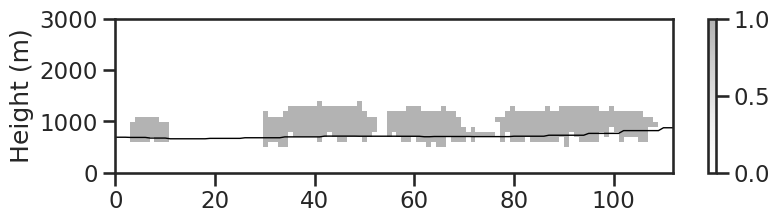

06844E


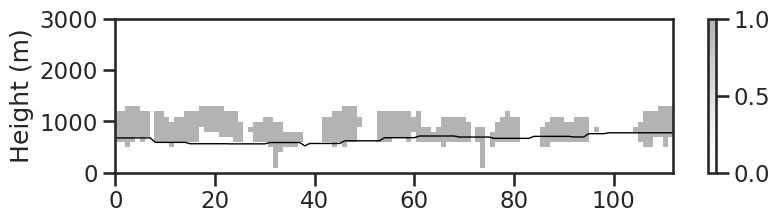

07093E


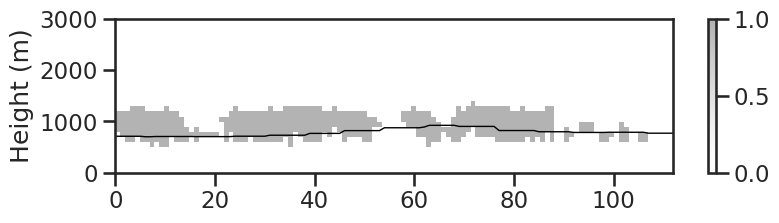

06439E


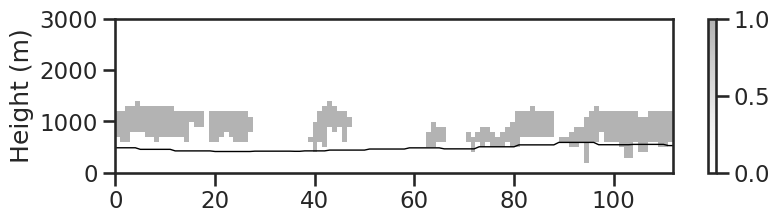

06548E


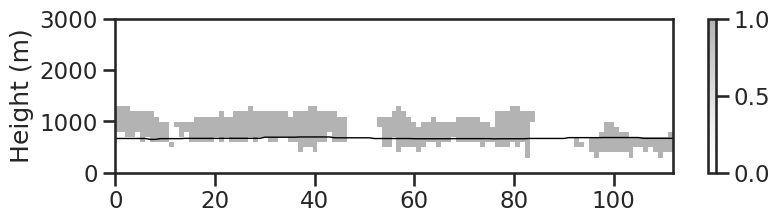

In [ ]:
for si in dfcat_sel.scene_id.unique():    
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = dffil[dffil.scene_id == si]
    print(dfex.orbit.values[0])
    if len(dfex) == 112:
        dfex = pd.concat([dfex, pd.DataFrame(dfex.iloc[-1,:]).T]).reset_index(drop=True)
    if len(dfex) != 113:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    if (dfex.ocean_mask != 1).all():
        print(f'skipping scene {si} with non-ocean points')
        continue

    profile_cat = add_profile(profile_cat, dfex.cbh_m, dfex.cth_m)

    plt.figure(figsize = (9,2))
    plt.imshow(profile_cat.T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Greys', alpha=0.3)
    plt.plot(dfex.lcl.values, color='black', lw=1, label='LCL')
    plt.colorbar()

    #plt.figure(figsize = (9,2))
    #im = plt.imshow((profile_cat * dfex.lwp.values[:, np.newaxis].astype(np.float32) / dfex.N_cloudy_pixels.values[:, np.newaxis].astype(np.float32)).T, origin='lower', aspect='auto', extent=[0,112,0,3000], 
    #           cmap='viridis', norm=LogNorm(1e-1, 5e2))
    #im = plt.imshow((profile_cat * dfex.lwp.values[:, np.newaxis].astype(np.float32)).T, origin='lower', aspect='auto', extent=[0,112,0,3000], 
    #           cmap='viridis', norm=LogNorm(1e-1, 5e2))
    ax = plt.gca()
    ax.set_ylabel('Height (m)')
    #plt.colorbar(im, label='LWP / g m$^{-2}$', pad=0.2)
    #ax = ax.twinx()
    #ax.plot(dfex.rwp.values, label='RWP', color='red', lw=1)
    #ax.set_ylim(1e-1, 1e2)
    #ax.set_ylabel('RWP (g/m2)', color='red')
    #ax.set_yscale('log')
    plt.show()

In [ ]:
def plot_ACMCAP_MCOP_for_scene_id(scene_id):
    orbit = dffil[dffil.scene_id == scene_id].orbit.values[0]
    lat_max = dffil[dffil.scene_id == scene_id].latitude.values.max()
    lat_min = dffil[dffil.scene_id == scene_id].latitude.values.min()

    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/*/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

    # load MCOP
    filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/*/*/*_{orbit}.h5')[0]
    MCOP = ecio.load_MCOP(filename)
    MCOP = MCOP.assign_coords(
        {
        'along_track': (
            ["along_track"],
            MCOP['along_track'].data,
            MCOP['along_track'].attrs
            ),
        'across_track': (
            ['across_track'],
            MCOP['across_track'].data,
            MCOP['across_track'].attrs
            )
        })
    along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
    along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
    MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
    MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

    # plot
    sns.set_context('talk')
    fig, axs = plt.subplots(2,1, figsize=(9,9), gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
    ACMCAP.liquid_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-6, vmax=1e-3, norm=LogNorm(), cmap='chiljet2', cbar_kwargs={'label': 'LWC (kg m$^{-3}$)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    axs[0].set_title(f'{orbit}, lat:{lat_min.round(2)}-{lat_max.round(2)}')

    ax = axs[1]
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', vmin=1e-2, vmax=1e0, norm=LogNorm(), add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    fig.tight_layout()
    plt.show()

07093E


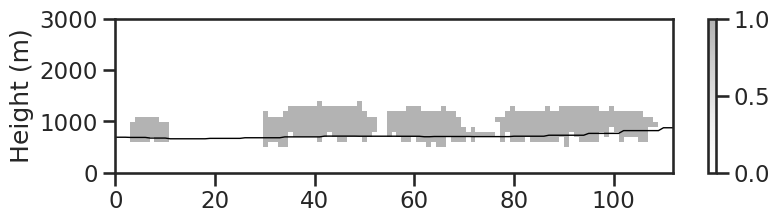

Selecting frame from 9 to 4877
Selecting frame from 444 to 11484


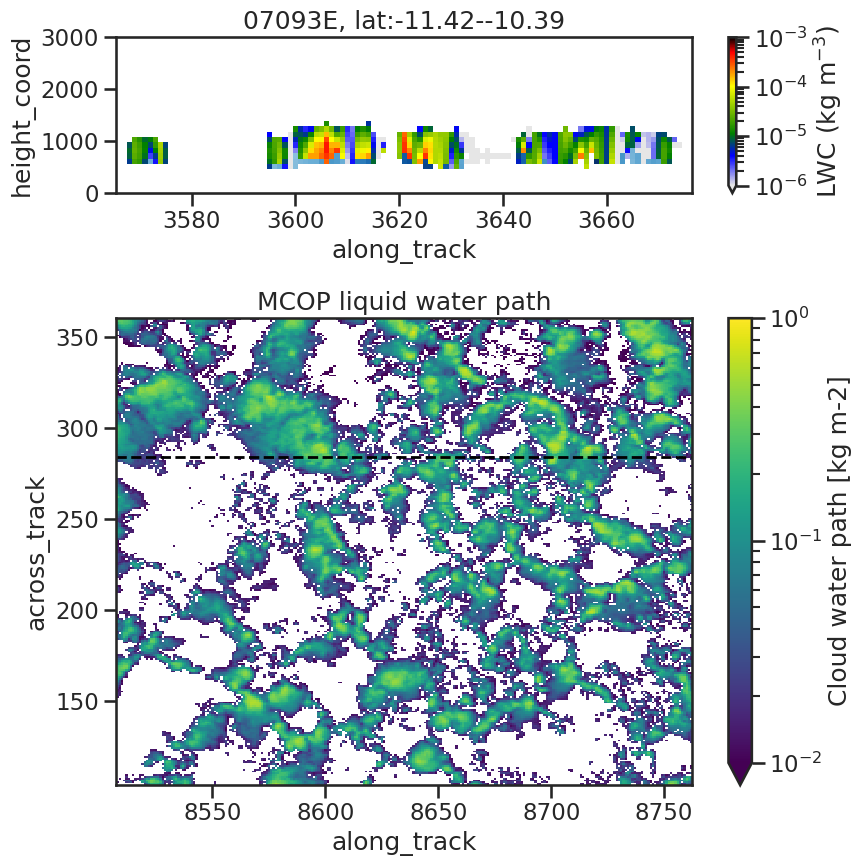

06844E


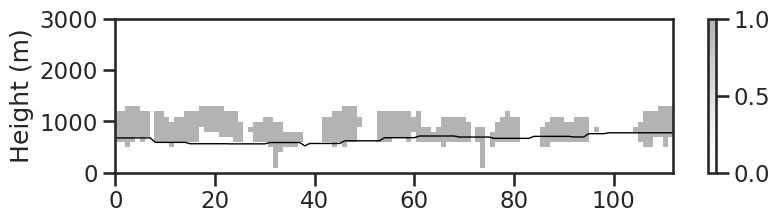

Selecting frame from 10 to 4877
Selecting frame from 440 to 11478


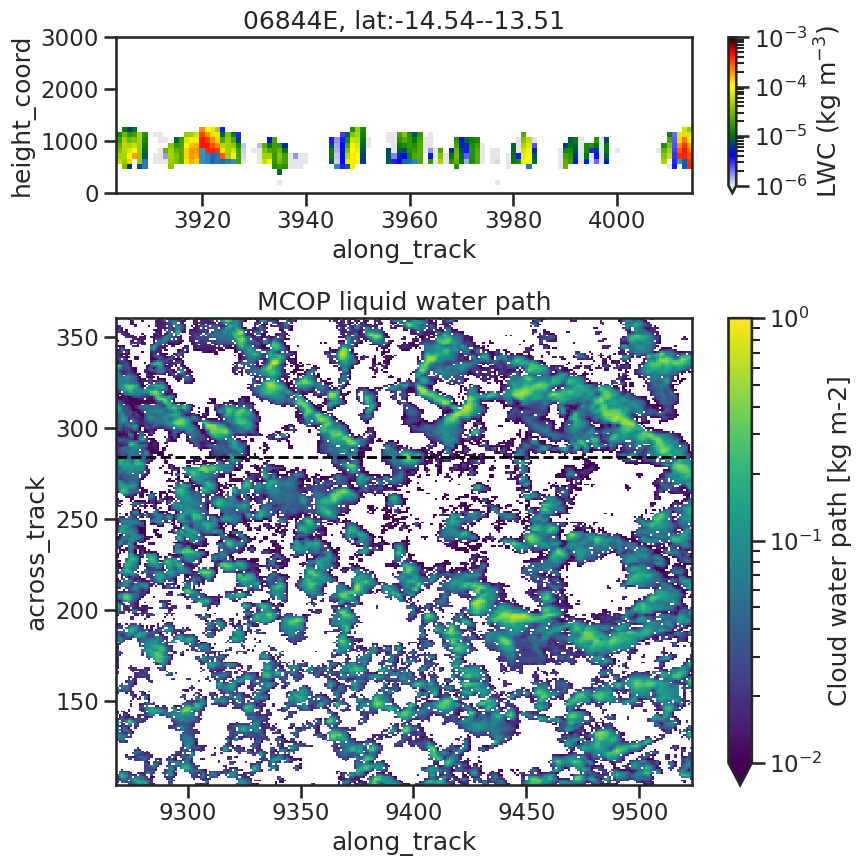

07093E


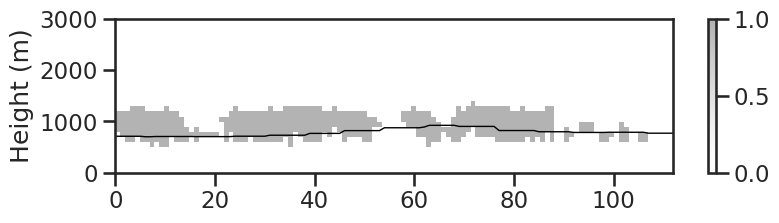

Selecting frame from 9 to 4877
Selecting frame from 444 to 11484


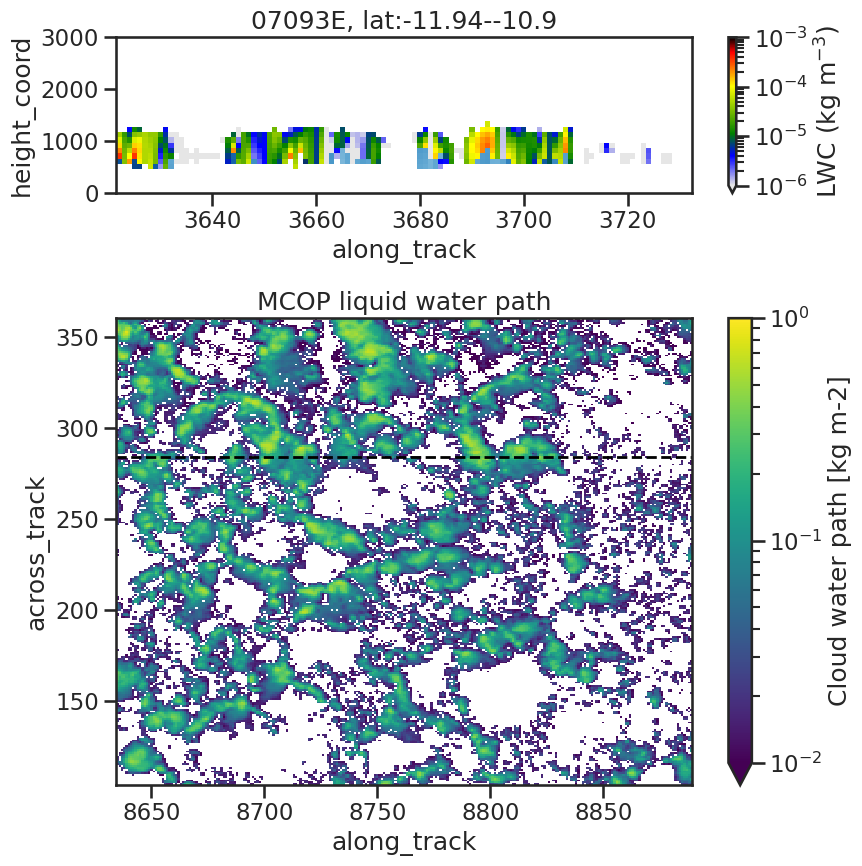

06439E


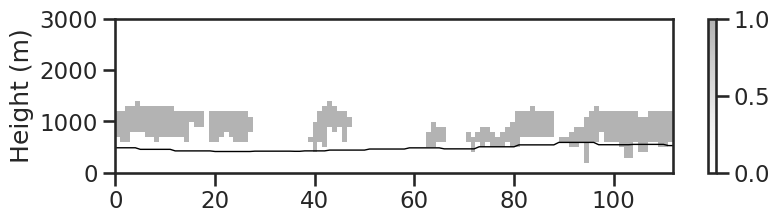

Selecting frame from 7 to 4875
Selecting frame from 433 to 11472


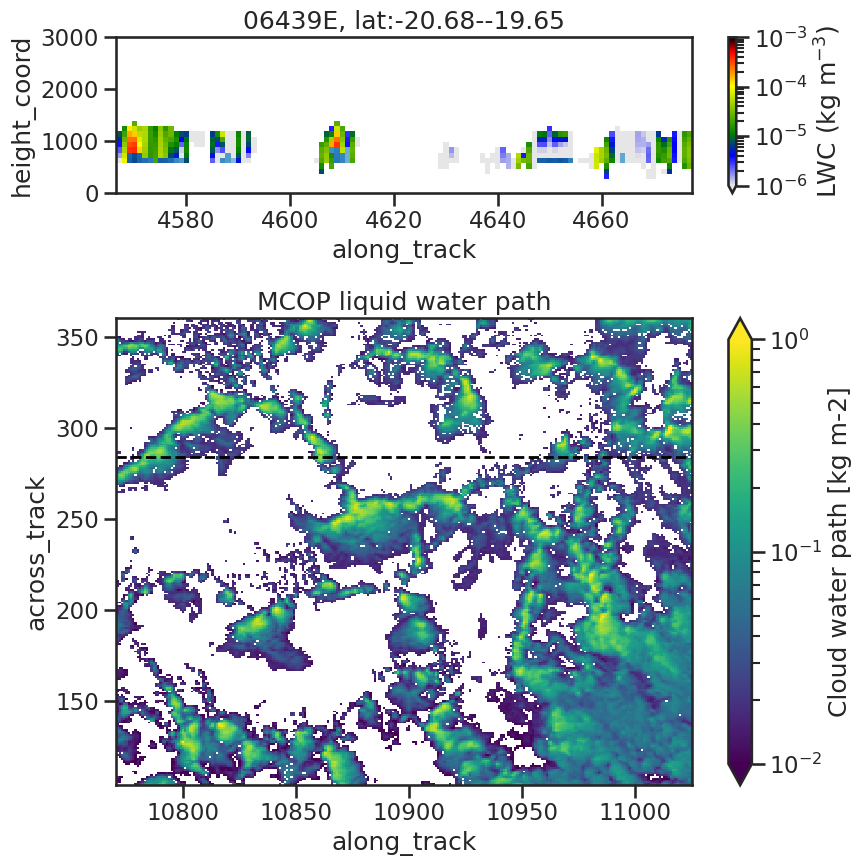

06548E


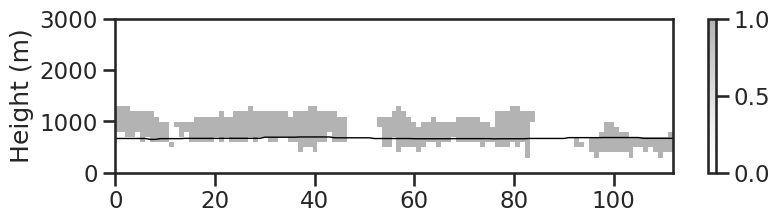

Selecting frame from 6 to 4874
Selecting frame from 431 to 11471


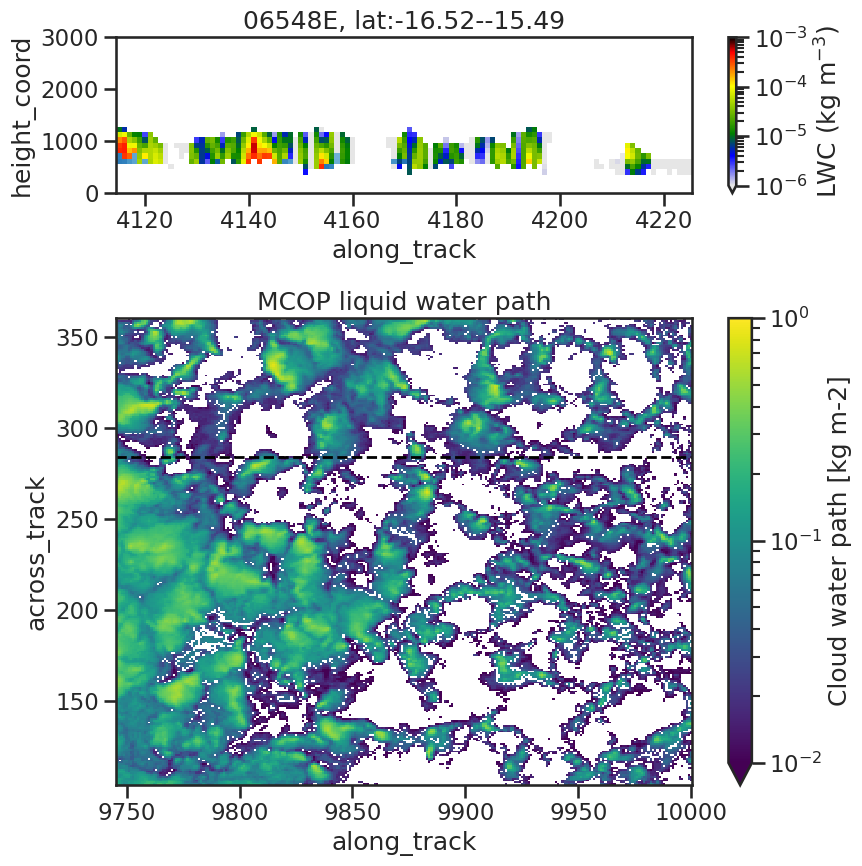

In [ ]:
for si in dfcat_sel.scene_id.unique()[0:10]:
    print(dffil[dffil.scene_id == si].orbit.values[0])
    
    profile_cat = xr.DataArray(np.zeros((113, 30)), dims=['along_track', 'height'], coords={'along_track': np.arange(113), 'height': np.arange(30)*100})
    #print(si)
    dfex = dffil[dffil.scene_id == si]
    if len(dfex) == 112:
        dfex = pd.concat([dfex, pd.DataFrame(dfex.iloc[-1,:]).T]).reset_index(drop=True)
    if len(dfex) != 113:
        print(f'skipping scene {si} with {len(dfex)} points')
        continue
    if dfex.cert.iloc[0] < 0.75:
        print(f'skipping scene {si} with low cert {dfex.cert.iloc[0]}')
        continue
    if (dfex.ocean_mask != 1).all():
        print(f'skipping scene {si} with non-ocean points')
        continue
    profile_cat = add_profile(profile_cat, dfex.cbh_m, dfex.cth_m)
    plt.figure(figsize = (9,2))
    plt.imshow(profile_cat.T, origin='lower', aspect='auto', extent=[0,112,0,3000], cmap='Greys', alpha=0.3)
    plt.plot(dfex.lcl.values, color='black', lw=1, label='LCL')
    plt.colorbar()
    ax = plt.gca()
    ax.set_ylabel('Height (m)')
    plt.show()
    
    plot_ACMCAP_MCOP_for_scene_id(si)